# Kalman AI — The First AI-Controlled Application

A Kalman filter estimates the state of a system; a **controller** uses that estimate to act on it. In this framework a controller is any callable `u = controller(x̂, P, t, ν)`, passed to the filter in place of a control sequence. The filter does not know what is behind it: a fixed gain, an optimal regulator, or a trained network. The estimation itself (predict, update, Kalman gain) stays classical throughout.

This notebook asks where a learned component helps, in three places:

| Layer | Classical method | Its assumption | Where learning may help | Sections |
|---|---|---|---|---|
| Control $\mathbf{u}$ | linear quadratic regulator (LQR) | linear dynamics, quadratic cost, no actuator limit | a hard actuator limit | 2–5c |
| Adapting $\mathbf{Q}$ and $\mathbf{R}$ | innovation-based rules | the noise changes in all states together | noise that changes in one state only | 6–7b |
| Choosing between models | Bayes' rule with Gaussian likelihoods | Gaussian noise | heavy-tailed noise | 8–10b |

Two kinds of weight appear below: $\mathbf{Q}$ and $\mathbf{R}$ are the noise covariances of the filter, and $Q_\text{cost}$ and $R_\text{cost}$ are the weights a controller puts on the state error and on the control effort.

In [1]:
%pip install numpy matplotlib scipy > /dev/null
%load_ext autoreload
%autoreload 2

import warnings; warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams["figure.dpi"] = 80
plt.rcParams["savefig.pad_inches"] = 0.05

import kalman; kalman.set_debug(0)
from kalman.helpers import cached_fit, cached, notebook_cache
from kalman.framework.filters import ExtendedKalmanFilter
from kalman.apps.vehicles import CarLaneModel
from kalman.framework import (
    ProportionalKalmanController,
    PIDKalmanController,
    LQRKalmanController,
    MPPIKalmanController,
    NeuralKalmanController,
    BoostKalmanController,
    AdaptiveQRKalmanController,
    NeuralAdaptiveQRKalmanController,
)

# Trained networks and slow benchmarks are stored here; KALMAN_CACHE_REFRESH=1 recomputes them.
CACHE = notebook_cache("12_KalmanAI")

Note: you may need to restart the kernel to use updated packages.

## 1 — The Test System: Lateral Lane-Keeping

A car drives at constant speed $v$ along a lane. Its state is

$$\mathbf{x} = [\,y,\ \psi,\ v\,]:$$

the lateral offset $y$ from the lane centre [m], the heading $\psi$ relative to the lane [rad], and the speed $v$ [m/s]. The control is the steering angle $\delta$ [rad]. With wheelbase $L = 2.7$ m and time step $\Delta t = 20$ ms, the bicycle model gives

$$y_{k+1} = y_k + v_k \sin\psi_k \, \Delta t, \qquad
  \psi_{k+1} = \psi_k + \frac{v_k \tan\delta_k}{L} \Delta t, \qquad
  v_{k+1} = v_k .$$

The steering is limited to $|\delta| \le 0.1$ rad. The car then turns with a lateral acceleration of at most $v^2\tan\delta/L \approx 8$ m/s² at 15 m/s, about what tyres hold on a dry road.

A lane camera measures $y$ with a standard deviation of 3 cm. The process noise per step has standard deviations of 1 cm in $y$, 1 mrad in $\psi$ and 1 cm/s in $v$.

The goal is to bring the car back to the lane centre from an offset of 0.5 m and a heading of 0.02 rad. Without steering, it drifts away:

state dimension n = 3, measurement dimension m = 1, control dimension l = 1


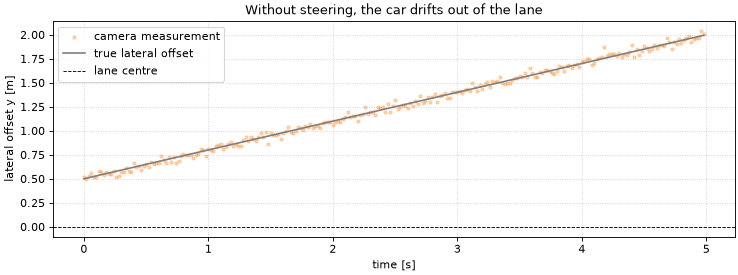

In [2]:
np.random.seed(42)

LATERAL_NOISE_STD = 0.03                # lane-camera noise, standard deviation [m]
X0 = np.array([[0.5], [0.02], [15.0]])  # start: y = 0.5 m, psi = 0.02 rad, v = 15 m/s

model = CarLaneModel("camera", fs=50, x0=X0, lateral_uncertainty=LATERAL_NOISE_STD)
print(f"state dimension n = {model.n}, measurement dimension m = {model.m}, control dimension l = {model.l}")

N = 250   # 5 seconds at 50 Hz
dt = 1.0 / model.fs

# The car with the steering held straight, and its noisy camera measurements
x_true = model.x0.copy()
zk_open = np.zeros((N, 1))
xk_open = np.zeros((N, 3))
for k in range(N):
    xk_open[k] = x_true.ravel()
    zk_open[k] = x_true[0, 0] + np.random.normal(0, LATERAL_NOISE_STD)
    x_true = model.f(x_true, u=np.array([[0.0]]), t=k * dt)

fig, ax = plt.subplots(figsize=(11, 3.5))
t = np.arange(N) * dt
ax.scatter(t, zk_open, s=8, alpha=0.3, color="tab:orange", label="camera measurement")
ax.plot(t, xk_open[:, 0], color="gray", lw=1.5, label="true lateral offset")
ax.axhline(0, color="black", ls="--", lw=0.8, label="lane centre")
ax.set_xlabel("time [s]"); ax.set_ylabel("lateral offset y [m]")
ax.set_title("Without steering, the car drifts out of the lane")
ax.legend(); ax.grid(True, ls=":", alpha=0.6); plt.show()

### Closing the Loop

A controller computes $\mathbf{u}$ from the filter's estimate $\hat{\mathbf{x}}$, not from the true state. To test controllers fairly, `closed_loop_run()` simulates the true car next to the filter. At each step it asks the controller for $\mathbf{u}$, moves the true car with that $\mathbf{u}$ plus process noise, measures it, and updates the filter with the measurement. Every controller below is run through it.

The argument `heavy=True` replaces the Gaussian process noise by Student-t noise with 3 degrees of freedom and the same variance. Such noise has rare but large jumps; we use it later to check whether a result depends on the noise being Gaussian.

In [3]:
from scipy.stats import t as t_dist

DF = 3  # degrees of freedom of the heavy-tailed (Student-t) process noise

def process_noise(std, size, heavy, rng):
    """Gaussian noise, or Student-t noise with the same standard deviation."""
    if not heavy:
        return rng.normal(0, std, size)
    scale = std * np.sqrt((DF - 2) / DF)
    return t_dist.rvs(DF, scale=scale, size=size, random_state=rng)

def closed_loop_run(controller, N, seed=0, heavy=False):
    """Run the true car and the filter together, steered by `controller`.
    Returns (record, xk_true, zk_hist)."""
    rng = np.random.default_rng(seed)
    model = controller.model
    ekf = ExtendedKalmanFilter(model)
    ekf.reset()

    x_true = model.x0.copy()
    dt_step = 1.0 / model.fs
    nu = np.zeros((model.m, 1))
    t_now = 0.0
    q_std = np.sqrt(np.diag(model.Q()))
    r_std = np.sqrt(np.diag(model.R()))

    xk_true = np.zeros((N, model.n))
    zk_hist = np.zeros((N, model.m))

    for k in range(N):
        u = controller(ekf.x, ekf.P, t_now, nu=nu)

        x_true = np.asarray(model.f(x_true, u=u, t=t_now), dtype=float).reshape(-1, 1)
        x_true = x_true + process_noise(q_std, model.n, heavy, rng).reshape(-1, 1)
        z = np.asarray(model.h(x_true, t=t_now), dtype=float).reshape(-1, 1)
        z = z + rng.normal(0, r_std).reshape(-1, 1)

        ekf.measurement.append(z)
        ekf.control.append(u.ravel())
        ekf.x, ekf.P, F = ekf.engine._predict(model, ekf.x, ekf.P, u=u, t=t_now)
        ekf.prior.append((ekf.x, ekf.P))
        ekf.transition.append(F)

        h_pred = model.h(ekf.x, t=t_now)
        nu = z - np.asarray(h_pred, dtype=float).reshape(-1, 1)
        ekf.innovation.append(nu)

        ekf.x, ekf.P = ekf.engine._update(model, ekf.x, ekf.P, z, t=t_now)
        ekf.posterior.append((ekf.x, ekf.P))

        xk_true[k] = x_true.ravel()
        zk_hist[k] = z.ravel()
        t_now += dt_step

    return ekf.get_record(), xk_true, zk_hist

def total_cost(controller):
    """Sum over the run of the cost per step, e^T Qcost e + u^T Rcost u."""
    return sum(c for _, c in controller.cost_log)

## 2 — Proportional Controller (Baseline)

All controllers below are scored with the same cost per step,

$$J_k = \mathbf{e}_k^\top Q_\text{cost}\,\mathbf{e}_k + \mathbf{u}_k^\top R_\text{cost}\,\mathbf{u}_k ,$$

where $\mathbf{e} = \hat{\mathbf{x}} - \mathbf{x}_\text{ref}$ is the error from the lane centre at cruise speed. `model.control_cost()` sets $Q_\text{cost}$ to 1 per m² of offset and $R_\text{cost}$ to 100 per rad² of steering: 1 m of offset costs as much as 0.1 rad of steering.

The simplest controller is proportional: $u = -K_p\,\mathbf{e}$. We steer on the offset (0.1 rad per m) and on the heading (0.7 rad per rad); the gains are set by hand.

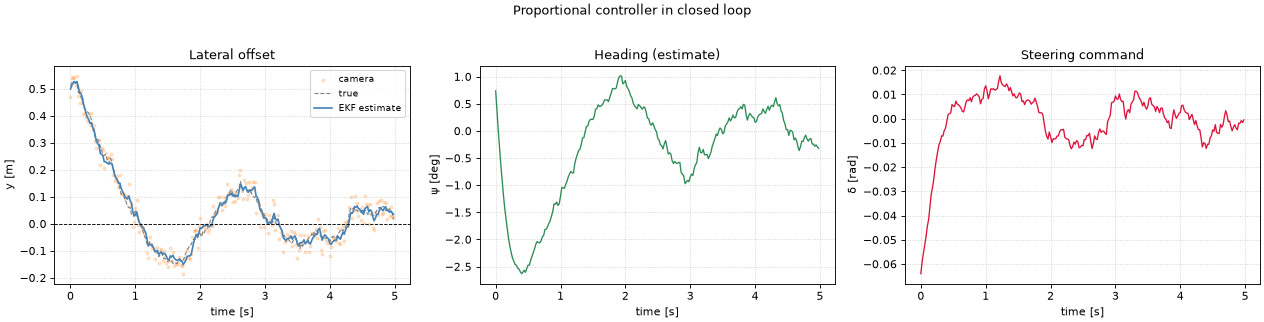

final true lateral offset: +0.015 m,  largest steering: 0.064 rad
total cost: 10.26


In [4]:
Qcost, Rcost, x_ref = model.control_cost()
COST = dict(Qcost=Qcost, Rcost=Rcost, x_ref=x_ref)       # the same cost weights for every controller

model_p = CarLaneModel("camera", fs=50, x0=X0, lateral_uncertainty=LATERAL_NOISE_STD)
Kp = np.array([[0.1, 0.7, 0.0]])   # [rad/m, rad/rad, rad/(m/s)]: offset and heading, not speed
ctrl_p = ProportionalKalmanController(model_p, Kp=Kp, **COST)

rec_p, xk_true_p, zk_ctrl = closed_loop_run(ctrl_p, N, seed=1)
est_p = np.asarray(rec_p.xk)
u_p = np.array([float(u.ravel()[0]) for _, u in ctrl_p.u_log])
t = np.arange(N) * dt

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].scatter(t, zk_ctrl, s=6, alpha=0.2, color="tab:orange", label="camera")
axes[0].plot(t, xk_true_p[:, 0], color="gray", lw=1, ls="--", label="true")
axes[0].plot(t, est_p[:, 0], color="steelblue", lw=1.5, label="EKF estimate")
axes[0].axhline(0, color="black", ls="--", lw=0.8)
axes[0].set_title("Lateral offset"); axes[0].set_ylabel("y [m]")
axes[0].legend(fontsize=8); axes[0].grid(True, ls=":", alpha=0.6)

axes[1].plot(t, np.degrees(est_p[:, 1]), color="seagreen", lw=1.2)
axes[1].set_title("Heading (estimate)"); axes[1].set_ylabel("ψ [deg]")
axes[1].grid(True, ls=":", alpha=0.6)

axes[2].plot(t, u_p, color="crimson", lw=1.2)
axes[2].set_title("Steering command"); axes[2].set_ylabel("δ [rad]")
axes[2].grid(True, ls=":", alpha=0.6)

for ax in axes: ax.set_xlabel("time [s]")
fig.suptitle("Proportional controller in closed loop", y=1.02)
plt.tight_layout(); plt.show()
cost_p = total_cost(ctrl_p)
print(f"final true lateral offset: {xk_true_p[-1, 0]:+.3f} m,  largest steering: {np.abs(u_p).max():.3f} rad")
print(f"total cost: {cost_p:.2f}")

## 3 — PID Controller

The PID (proportional-integral-derivative) controller adds two terms to the proportional one:

$$u = -K_p \, e - K_i \int e \, dt - K_d \, \dot{e} .$$

The integral term removes a constant offset that a proportional controller would leave; the derivative term damps oscillations. Here there is no constant disturbance to remove, so we do not expect much from it.

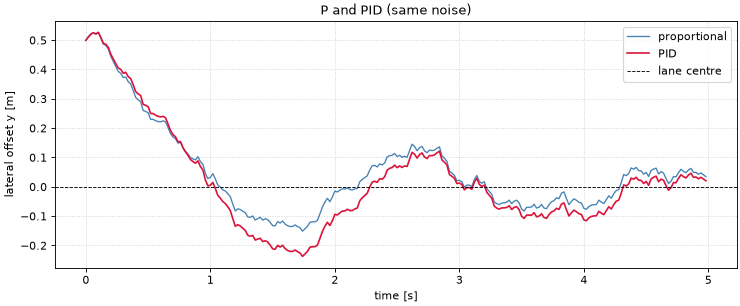

total cost: proportional 10.26,  PID 11.71


In [5]:
model_pid = CarLaneModel("camera", fs=50, x0=X0, lateral_uncertainty=LATERAL_NOISE_STD)
ctrl_pid = PIDKalmanController(
    model_pid,
    Kp=np.array([[0.1, 0.7, 0.0]]),
    Ki=np.array([[0.02, 0.0, 0.0]]),   # integral of the offset
    Kd=np.array([[0.0, 0.05, 0.0]]),   # derivative of the heading
    **COST,
)

rec_pid, xk_true_pid, _ = closed_loop_run(ctrl_pid, N, seed=1)
est_pid = np.asarray(rec_pid.xk)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(t, est_p[:, 0], color="steelblue", lw=1.2, label="proportional")
ax.plot(t, est_pid[:, 0], color="crimson", lw=1.5, label="PID")
ax.axhline(0, color="black", ls="--", lw=0.8, label="lane centre")
ax.set_xlabel("time [s]"); ax.set_ylabel("lateral offset y [m]")
ax.set_title("P and PID (same noise)")
ax.legend(); ax.grid(True, ls=":", alpha=0.6); plt.show()

cost_pid = total_cost(ctrl_pid)
print(f"total cost: proportional {cost_p:.2f},  PID {cost_pid:.2f}")

## 4 — LQR Controller

The **linear quadratic regulator** (LQR) finds the constant gain $K_\text{lqr}$ in $u = -K_\text{lqr}\,\mathbf{e}$ that minimises the total cost $\sum_k J_k$ for a linear model. It linearises the model once ($\mathbf{F}$ and the control matrix $\mathbf{B}$) and solves a Riccati equation for the gain. As long as the car stays near the lane centre, the model is nearly linear and the steering stays below its limit, so LQR is the optimum here.

LQR gain K_lqr = [0.096  0.7345 0.001 ]   [rad/m, rad/rad, rad/(m/s)]


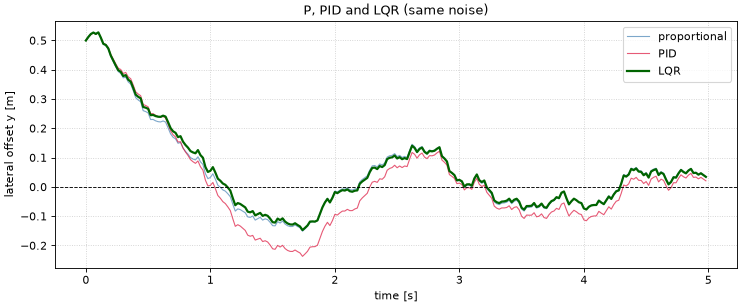

largest LQR steering: 0.063 rad (limit 0.1 rad)
total cost: P 10.26,  PID 11.71,  LQR 10.06


In [6]:
model_lqr = CarLaneModel("camera", fs=50, x0=X0, lateral_uncertainty=LATERAL_NOISE_STD)
ctrl_lqr = LQRKalmanController(model_lqr, **COST)
ctrl_lqr.fit()
print(f"LQR gain K_lqr = {ctrl_lqr.K.ravel().round(4)}   [rad/m, rad/rad, rad/(m/s)]")

rec_lqr, xk_true_lqr, _ = closed_loop_run(ctrl_lqr, N, seed=1)
est_lqr = np.asarray(rec_lqr.xk)
u_lqr = np.array([float(u.ravel()[0]) for _, u in ctrl_lqr.u_log])

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(t, est_p[:, 0], color="steelblue", lw=1, alpha=0.7, label="proportional")
ax.plot(t, est_pid[:, 0], color="crimson", lw=1, alpha=0.7, label="PID")
ax.plot(t, est_lqr[:, 0], color="darkgreen", lw=2, label="LQR")
ax.axhline(0, color="black", ls="--", lw=0.8)
ax.set_xlabel("time [s]"); ax.set_ylabel("lateral offset y [m]")
ax.set_title("P, PID and LQR (same noise)")
ax.legend(); ax.grid(True, ls=":", alpha=0.6); plt.show()

cost_lqr = total_cost(ctrl_lqr)
print(f"largest LQR steering: {np.abs(u_lqr).max():.3f} rad (limit {model_lqr.steer_limit} rad)")
print(f"total cost: P {cost_p:.2f},  PID {cost_pid:.2f},  LQR {cost_lqr:.2f}")

LQR has the lowest cost. The hand-tuned proportional controller comes within a few percent, because its gains happen to be close to $K_\text{lqr}$; the PID controller costs more: with no constant disturbance to remove, its extra terms only add steering.

## 5 — A Neural Controller Where LQR Is Optimal

**MPPI** (model predictive path integral) is a planner. At every step it tries many random steering sequences on the model over a short horizon, and averages them, weighting each by $e^{-J/\lambda}$ where $J$ is its cost. It uses the full nonlinear model, steering limit included, but it is expensive: thousands of model evaluations per step.

`NeuralKalmanController` trains a small multilayer perceptron (MLP), a network of two hidden layers, to imitate MPPI. `fit_mppi()` runs MPPI on simulated episodes, records every (state, steering) decision, and fits the network to them. At run time the controller evaluates the network once per step.

In this scenario the steering stays below its limit and the model is nearly linear, so LQR is the optimum and the network can at best come close to it.

[cache] loading ctrl_nn.npz (set KALMAN_CACHE_REFRESH=1 to retrain)


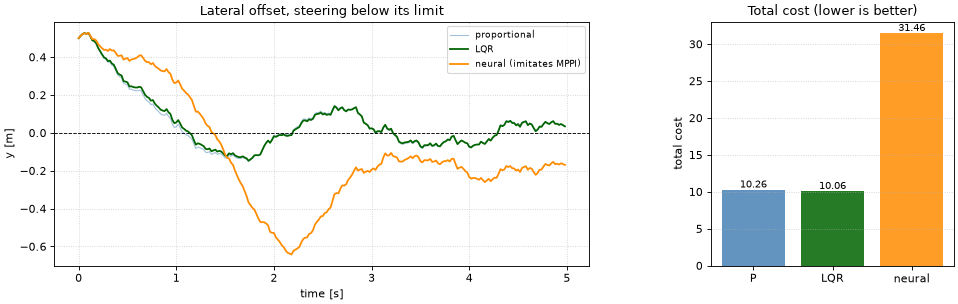

total cost: P 10.26,  LQR 10.06,  neural 31.46  (neural / LQR = 3.13)


In [7]:
model_nn = CarLaneModel("camera", fs=50, x0=X0, lateral_uncertainty=LATERAL_NOISE_STD)
ctrl_nn = NeuralKalmanController(model_nn, hidden=32, **COST)

# Training: 10 episodes of 80 steps starting around X0; MPPI tries 150 sequences of 1 s (50 steps)
# at every step. The weights are stored in the cache after the first run.
cached_fit(CACHE / "ctrl_nn.npz",
           lambda: ctrl_nn.fit_mppi(n_rollouts=150, horizon=50, noise_sigma=0.03, lam=1.0,
                                    epochs=300, lr=5e-4, seed=42,
                                    n_episodes=10, rollout_steps=80, x0_std=0.2, n_iters=2),
           load=ctrl_nn.load, save=ctrl_nn.save)

rec_nn, xk_true_nn, _ = closed_loop_run(ctrl_nn, N, seed=1)
est_nn = np.asarray(rec_nn.xk)
cost_nn = total_cost(ctrl_nn)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(t, est_p[:, 0], color="steelblue", lw=1, alpha=0.5, label="proportional")
axes[0].plot(t, est_lqr[:, 0], color="darkgreen", lw=1.6, label="LQR")
axes[0].plot(t, est_nn[:, 0], color="darkorange", lw=1.6, label="neural (imitates MPPI)")
axes[0].axhline(0, color="black", ls="--", lw=0.8)
axes[0].set_xlabel("time [s]"); axes[0].set_ylabel("y [m]")
axes[0].set_title("Lateral offset, steering below its limit")
axes[0].legend(fontsize=8); axes[0].grid(True, ls=":", alpha=0.6)

costs_names = ["P", "LQR", "neural"]
costs_vals  = [cost_p, cost_lqr, cost_nn]
axes[1].bar(costs_names, costs_vals, color=["steelblue", "darkgreen", "darkorange"], alpha=0.85)
axes[1].set_ylabel("total cost"); axes[1].set_title("Total cost (lower is better)")
for i, v in enumerate(costs_vals):
    axes[1].text(i, v + max(costs_vals) * 0.01, f"{v:.2f}", ha="center", fontsize=9)
axes[1].grid(True, axis="y", ls=":", alpha=0.6)
axes[1].set_box_aspect(1)
plt.tight_layout(); plt.show()

print(f"total cost: P {cost_p:.2f},  LQR {cost_lqr:.2f},  neural {cost_nn:.2f}  (neural / LQR = {cost_nn / cost_lqr:.2f})")

The network costs about three times as much as LQR: it overshoots to the other side of the lane and settles with an offset. Its teacher, MPPI with a horizon of 1 s and 150 samples per step, is far from optimal in this regime, and the network adds its own fitting error. Imitating a planner can only be as good as the planner.

### Does Non-Gaussian Process Noise Change This?

For a linear model with quadratic cost, the optimal feedback law depends only on the mean and covariance of the noise, not on its shape (this is called **certainty equivalence**). Heavy-tailed noise with the same variance should therefore leave the LQR cost about unchanged. We check it on 15 runs with Gaussian and with Student-t process noise.

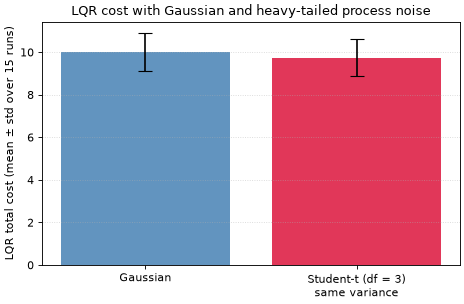

LQR cost, Gaussian noise:     9.99 (± 0.90)
LQR cost, heavy-tailed noise: 9.74 (± 0.86)


In [8]:
def lqr_cost_multi_seed(heavy, n_seeds=15, seed_base=200):
    costs = []
    for s in range(n_seeds):
        model_s = CarLaneModel("camera", fs=50, x0=X0, lateral_uncertainty=LATERAL_NOISE_STD)
        ctrl_s = LQRKalmanController(model_s, **COST)
        ctrl_s.fit()
        closed_loop_run(ctrl_s, N, seed=seed_base + s, heavy=heavy)
        costs.append(total_cost(ctrl_s))
    return np.mean(costs), np.std(costs)

mean_g, std_g = lqr_cost_multi_seed(heavy=False)
mean_h, std_h = lqr_cost_multi_seed(heavy=True)

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["Gaussian", "Student-t (df = 3)\nsame variance"], [mean_g, mean_h],
       yerr=[std_g, std_h], color=["steelblue", "crimson"], alpha=0.85, capsize=6)
ax.set_ylabel("LQR total cost (mean ± std over 15 runs)")
ax.set_title("LQR cost with Gaussian and heavy-tailed process noise")
ax.grid(True, axis="y", ls=":", alpha=0.5)
plt.tight_layout(); plt.show()

print(f"LQR cost, Gaussian noise:     {mean_g:.2f} (± {std_g:.2f})")
print(f"LQR cost, heavy-tailed noise: {mean_h:.2f} (± {std_h:.2f})")

The two costs agree within their run-to-run spread, as certainty equivalence predicts.

## 5b — A Hard Actuator Limit

Now the car starts a full lane width (3.5 m) away from the centre, and the steering weight is lowered to $R_\text{cost} = 10$ per rad². The LQR gain then asks for far more steering than the 0.1 rad the car can deliver, and the car simply clips the command. LQR's gain was computed without the limit, so it cannot plan for it. MPPI plans with the clipped model and keeps its commands inside the limit.

The cost is charged on the steering actually delivered, not on the clipped excess.

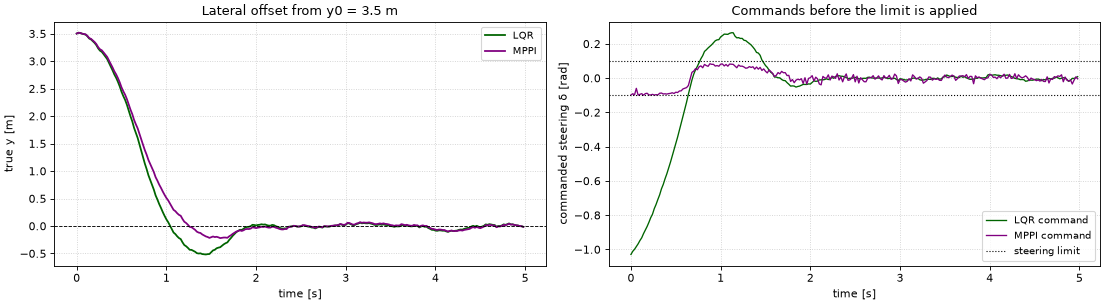

largest command: LQR 1.03 rad, MPPI 0.10 rad  (limit 0.1 rad)
overshoot past the centre: LQR 0.52 m, MPPI 0.22 m
total cost: LQR 331.6,  MPPI 341.7  (MPPI lower by -3.1%)


In [9]:
Qcost_sat = np.diag([1.0, 0.0, 0.0])
Rcost_sat = np.array([[10.0]])                    # cheaper steering: LQR now asks for much more than 0.1 rad
COST_SAT = dict(Qcost=Qcost_sat, Rcost=Rcost_sat, x_ref=x_ref)
X0_SAT = np.array([[3.5], [0.0], [15.0]])         # one lane width away from the centre
N_sat = 250
t_sat = np.arange(N_sat) * dt
MPPI_KW = dict(n_rollouts=100, horizon=40, noise_sigma=0.05, lam=1.0, n_iters=3, seed=7)   # horizon 0.8 s

model_lqr_sat = CarLaneModel("camera", fs=50, x0=X0_SAT, lateral_uncertainty=LATERAL_NOISE_STD)
ctrl_lqr_sat = LQRKalmanController(model_lqr_sat, **COST_SAT)
ctrl_lqr_sat.fit()
_, xk_lqr_sat, _ = closed_loop_run(ctrl_lqr_sat, N_sat, seed=2)
u_lqr_sat = np.array([float(u.ravel()[0]) for _, u in ctrl_lqr_sat.u_log])

model_mppi_sat = CarLaneModel("camera", fs=50, x0=X0_SAT, lateral_uncertainty=LATERAL_NOISE_STD)
ctrl_mppi_sat = MPPIKalmanController(model_mppi_sat, **MPPI_KW, **COST_SAT)
_, xk_mppi_sat, _ = closed_loop_run(ctrl_mppi_sat, N_sat, seed=2)
u_mppi_sat = np.array([float(u.ravel()[0]) for _, u in ctrl_mppi_sat.u_log])

cost_lqr_sat = total_cost(ctrl_lqr_sat)
cost_mppi_sat = total_cost(ctrl_mppi_sat)
steer_limit = model_lqr_sat.steer_limit

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(t_sat, xk_lqr_sat[:, 0], color="darkgreen", lw=1.6, label="LQR")
axes[0].plot(t_sat, xk_mppi_sat[:, 0], color="purple", lw=1.6, label="MPPI")
axes[0].axhline(0, color="black", ls="--", lw=0.8)
axes[0].set_xlabel("time [s]"); axes[0].set_ylabel("true y [m]")
axes[0].set_title(f"Lateral offset from y0 = {X0_SAT[0, 0]} m")
axes[0].legend(fontsize=9); axes[0].grid(True, ls=":", alpha=0.6)

axes[1].plot(t_sat, u_lqr_sat, color="darkgreen", lw=1.2, label="LQR command")
axes[1].plot(t_sat, u_mppi_sat, color="purple", lw=1.2, label="MPPI command")
axes[1].axhline(steer_limit, color="black", ls=":", lw=1, label="steering limit")
axes[1].axhline(-steer_limit, color="black", ls=":", lw=1)
axes[1].set_xlabel("time [s]"); axes[1].set_ylabel("commanded steering δ [rad]")
axes[1].set_title("Commands before the limit is applied")
axes[1].legend(fontsize=9); axes[1].grid(True, ls=":", alpha=0.6)
plt.tight_layout(); plt.show()

print(f"largest command: LQR {np.abs(u_lqr_sat).max():.2f} rad, MPPI {np.abs(u_mppi_sat).max():.2f} rad  (limit {steer_limit} rad)")
print(f"overshoot past the centre: LQR {-xk_lqr_sat[:, 0].min():.2f} m, MPPI {-xk_mppi_sat[:, 0].min():.2f} m")
print(f"total cost: LQR {cost_lqr_sat:.1f},  MPPI {cost_mppi_sat:.1f}  "
      f"(MPPI lower by {(1 - cost_mppi_sat / cost_lqr_sat) * 100:+.1f}%)")

LQR commands up to ten times the limit, so the car steers at full lock until it is close to the centre, and then overshoots by about half a metre. MPPI keeps its commands inside the limit and overshoots less than half as far. Its total cost is nevertheless a few percent higher than LQR's. LQR reaches the centre sooner, and the cost of being far from the lane early on outweighs that of the overshoot; MPPI, with a horizon of 0.8 s and 100 random samples per step, is only an approximate optimiser.

## 5c — Distilling the Planner Into a Neural Policy

MPPI evaluates the model 12,000 times per step here (100 sequences of 40 steps, refined 3 times), every 20 ms. A network that imitates it needs one evaluation. We train `NeuralKalmanController` on MPPI's decisions in this saturated scenario and compare the three controllers.

[cache] loading ctrl_nn_sat.npz (set KALMAN_CACHE_REFRESH=1 to retrain)


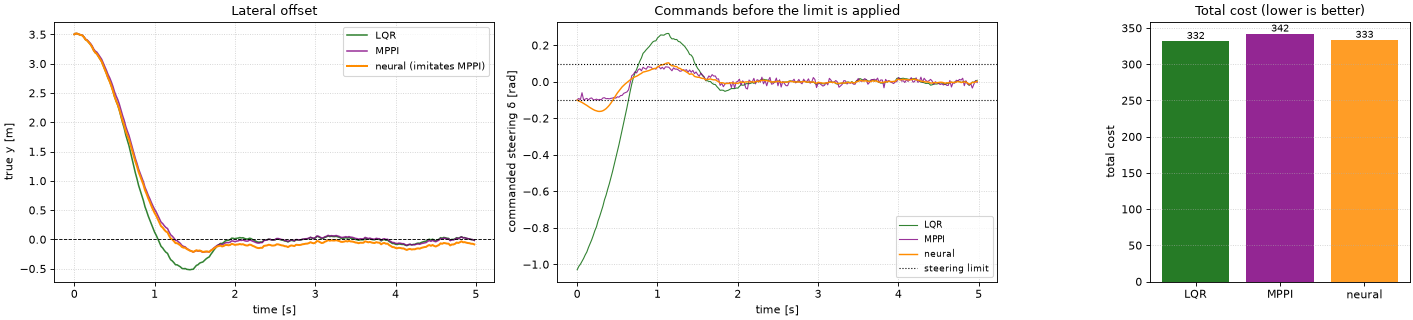

controller  total cost   vs LQR  overshoot
LQR              331.6    +0.0%      0.52 m
MPPI             341.7    -3.1%      0.22 m
neural           333.1    -0.5%      0.21 m


In [10]:
model_nn_sat = CarLaneModel("camera", fs=50, x0=X0_SAT, lateral_uncertainty=LATERAL_NOISE_STD)
ctrl_nn_sat = NeuralKalmanController(model_nn_sat, hidden=48, **COST_SAT)

# Training: 12 episodes of 150 steps starting around X0_SAT (spread 0.5 in every state);
# the MPPI teacher tries 60 sequences of 40 steps at every step. Cached after the first run.
cached_fit(CACHE / "ctrl_nn_sat.npz",
           lambda: ctrl_nn_sat.fit_mppi(n_rollouts=60, horizon=40, noise_sigma=0.05, lam=1.0,
                                        epochs=600, lr=4e-4, seed=3,
                                        n_episodes=12, rollout_steps=150, x0_std=0.5, n_iters=3),
           load=ctrl_nn_sat.load, save=ctrl_nn_sat.save)

_, xk_nn_sat, _ = closed_loop_run(ctrl_nn_sat, N_sat, seed=2)
u_nn_sat = np.array([float(u.ravel()[0]) for _, u in ctrl_nn_sat.u_log])
cost_nn_sat = total_cost(ctrl_nn_sat)

fig, axes = plt.subplots(1, 3, figsize=(19, 4.2))
axes[0].plot(t_sat, xk_lqr_sat[:, 0], color="darkgreen", lw=1.4, alpha=0.8, label="LQR")
axes[0].plot(t_sat, xk_mppi_sat[:, 0], color="purple", lw=1.4, alpha=0.8, label="MPPI")
axes[0].plot(t_sat, xk_nn_sat[:, 0], color="darkorange", lw=1.8, label="neural (imitates MPPI)")
axes[0].axhline(0, color="black", ls="--", lw=0.8)
axes[0].set_xlabel("time [s]"); axes[0].set_ylabel("true y [m]")
axes[0].set_title("Lateral offset")
axes[0].legend(fontsize=9); axes[0].grid(True, ls=":", alpha=0.6)

axes[1].plot(t_sat, u_lqr_sat, color="darkgreen", lw=1.0, alpha=0.8, label="LQR")
axes[1].plot(t_sat, u_mppi_sat, color="purple", lw=1.0, alpha=0.8, label="MPPI")
axes[1].plot(t_sat, u_nn_sat, color="darkorange", lw=1.3, label="neural")
axes[1].axhline(steer_limit, color="black", ls=":", lw=1, label="steering limit")
axes[1].axhline(-steer_limit, color="black", ls=":", lw=1)
axes[1].set_xlabel("time [s]"); axes[1].set_ylabel("commanded steering δ [rad]")
axes[1].set_title("Commands before the limit is applied")
axes[1].legend(fontsize=8); axes[1].grid(True, ls=":", alpha=0.6)

names_sat = ["LQR", "MPPI", "neural"]
costs_sat = [cost_lqr_sat, cost_mppi_sat, cost_nn_sat]
bars = axes[2].bar(names_sat, costs_sat, color=["darkgreen", "purple", "darkorange"], alpha=0.85)
for bar, v in zip(bars, costs_sat):
    axes[2].text(bar.get_x() + bar.get_width() / 2, v + max(costs_sat) * 0.01,
                f"{v:.0f}", ha="center", fontsize=9)
axes[2].set_ylabel("total cost"); axes[2].set_title("Total cost (lower is better)")
axes[2].grid(True, axis="y", ls=":", alpha=0.6)
axes[2].set_box_aspect(1)
plt.tight_layout(); plt.show()

print(f"{'controller':<10} {'total cost':>11} {'vs LQR':>8} {'overshoot':>10}")
for name, cost, xs in [("LQR", cost_lqr_sat, xk_lqr_sat), ("MPPI", cost_mppi_sat, xk_mppi_sat),
                       ("neural", cost_nn_sat, xk_nn_sat)]:
    print(f"{name:<10} {cost:>11.1f} {(1 - cost / cost_lqr_sat) * 100:>+7.1f}% {-xs[:, 0].min():>9.2f} m")

The network copies its teacher closely here: it overshoots as little as MPPI, and its cost is within one percent of LQR's.

So planning around the limit changes how the car gets back, not how much it costs: LQR overshoots by about half a metre, MPPI and its network approach gently, and the total cost comes out about the same. Clipped LQR is hard to beat in this scenario.

### Does Heavy-Tailed Noise Change the Saturated Case?

Once the limit is active the problem is no longer linear, so certainty equivalence no longer applies, and the noise shape could matter. We repeat the LQR–MPPI comparison on 4 runs with Gaussian and 4 with Student-t process noise.

[cache] loading saturated_costs.pkl (set KALMAN_CACHE_REFRESH=1 to recompute)


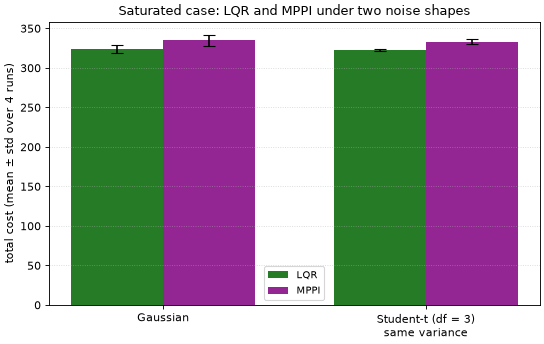

Gaussian:     LQR 323.6 (±5.1)  MPPI 334.9 (±6.6)  MPPI lower by -3.5% (runs: [-3.7 -2.3 -3.5 -4.4])
heavy-tailed: LQR 322.7 (±1.5)  MPPI 333.4 (±2.8)  MPPI lower by -3.3% (runs: [-2.9 -3.3 -4.  -2.9])


In [11]:
def saturated_costs_multi_seed(heavy, n_seeds=4, seed_base=300):
    lqr_costs, mppi_costs = [], []
    for s in range(n_seeds):
        model_l = CarLaneModel("camera", fs=50, x0=X0_SAT, lateral_uncertainty=LATERAL_NOISE_STD)
        ctrl_l = LQRKalmanController(model_l, **COST_SAT)
        ctrl_l.fit()
        closed_loop_run(ctrl_l, N_sat, seed=seed_base + s, heavy=heavy)
        lqr_costs.append(total_cost(ctrl_l))

        model_m = CarLaneModel("camera", fs=50, x0=X0_SAT, lateral_uncertainty=LATERAL_NOISE_STD)
        ctrl_m = MPPIKalmanController(model_m, **MPPI_KW, **COST_SAT)
        closed_loop_run(ctrl_m, N_sat, seed=seed_base + s, heavy=heavy)
        mppi_costs.append(total_cost(ctrl_m))
    return np.array(lqr_costs), np.array(mppi_costs)

# 8 MPPI runs take several minutes; the result is cached after the first run.
_costs = cached(CACHE / "saturated_costs.pkl", lambda: dict(
    zip(("lqr_g", "mppi_g", "lqr_h", "mppi_h"),
        saturated_costs_multi_seed(heavy=False) + saturated_costs_multi_seed(heavy=True))))
lqr_g, mppi_g, lqr_h, mppi_h = (_costs[k] for k in ("lqr_g", "mppi_g", "lqr_h", "mppi_h"))

adv_g = (1 - mppi_g / lqr_g) * 100
adv_h = (1 - mppi_h / lqr_h) * 100

fig, ax = plt.subplots(figsize=(7, 4.5))
x_pos = np.arange(2)
w = 0.35
ax.bar(x_pos - w/2, [lqr_g.mean(), lqr_h.mean()], width=w,
       yerr=[lqr_g.std(), lqr_h.std()], color="darkgreen", alpha=0.85, capsize=5, label="LQR")
ax.bar(x_pos + w/2, [mppi_g.mean(), mppi_h.mean()], width=w,
       yerr=[mppi_g.std(), mppi_h.std()], color="purple", alpha=0.85, capsize=5, label="MPPI")
ax.set_xticks(x_pos); ax.set_xticklabels(["Gaussian", "Student-t (df = 3)\nsame variance"])
ax.set_ylabel("total cost (mean ± std over 4 runs)")
ax.set_title("Saturated case: LQR and MPPI under two noise shapes")
ax.legend(fontsize=9); ax.grid(True, axis="y", ls=":", alpha=0.5)
plt.tight_layout(); plt.show()

print(f"Gaussian:     LQR {lqr_g.mean():.1f} (±{lqr_g.std():.1f})  MPPI {mppi_g.mean():.1f} "
      f"(±{mppi_g.std():.1f})  MPPI lower by {adv_g.mean():+.1f}% (runs: {np.round(adv_g, 1)})")
print(f"heavy-tailed: LQR {lqr_h.mean():.1f} (±{lqr_h.std():.1f})  MPPI {mppi_h.mean():.1f} "
      f"(±{mppi_h.std():.1f})  MPPI lower by {adv_h.mean():+.1f}% (runs: {np.round(adv_h, 1)})")

The noise shape does not change the comparison: in both cases MPPI costs a few percent more than LQR, in every run.

## 6 — BoostKalmanController: Trusting Measurements More After a Surprise

This and the next controller are simple rules, not learned models; they are here as the baseline a learned version would have to beat.

The **normalised innovation squared** (NIS), $\nu^\top \mathbf{S}^{-1}\nu$ with $\mathbf{S}$ the predicted innovation covariance, measures how surprised the filter is by a measurement; for a correct filter its mean is $m$, the measurement dimension. When the average NIS over the last few steps exceeds a threshold, `BoostKalmanController` divides $\mathbf{R}$ by a factor. The Kalman gain $\mathbf{K}$ then grows, and the filter follows the measurements more closely.

The test is a lane change: the car moves 3.5 m sideways in 2 s. The filter runs without the steering input, so it expects the car to go straight, and it lags behind.

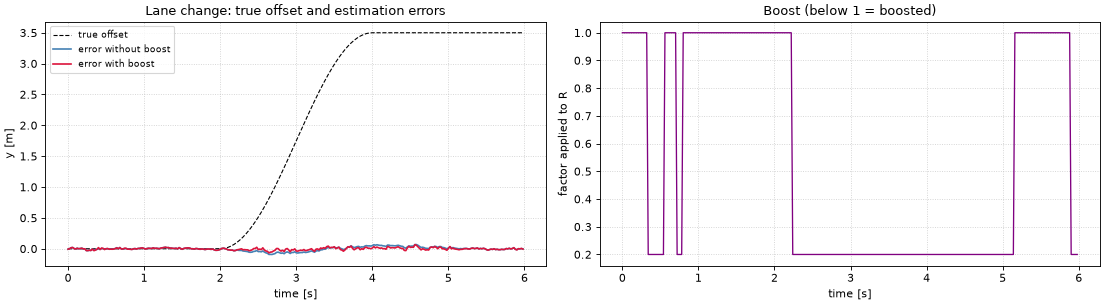

RMSE during the lane change: without boost 4.5 cm, with boost 2.4 cm


In [12]:
# A lane change: 3.5 m to the left between t = 2 s and t = 4 s (smooth, peak lateral speed 2.7 m/s)
N_boost = 300
t_plot = np.arange(N_boost) / 50
truth_change = np.where(t_plot < 2, 0.0,
                        np.where(t_plot > 4, 3.5, 3.5 * (1 - np.cos(np.pi * (t_plot - 2) / 2)) / 2))
zk_change = (truth_change + np.random.normal(0, LATERAL_NOISE_STD, N_boost)).reshape(-1, 1)

# Without the boost
model_nb = CarLaneModel("camera", fs=50, lateral_uncertainty=LATERAL_NOISE_STD)
rec_nb = ExtendedKalmanFilter(model_nb).forward(zk_change)

# With the boost: R divided by 5 while the mean NIS over 5 steps exceeds 2
model_b = CarLaneModel("camera", fs=50, lateral_uncertainty=LATERAL_NOISE_STD)
boost = BoostKalmanController(model_b, boost_factor=5.0, threshold=2.0, window=5)
rec_b = ExtendedKalmanFilter(model_b).forward(zk_change, uk=boost)

est_nb, est_b = np.asarray(rec_nb.xk)[:, 0], np.asarray(rec_b.xk)[:, 0]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(t_plot, truth_change, color="black", ls="--", lw=1, label="true offset")
axes[0].plot(t_plot, est_nb - truth_change, color="steelblue", lw=1.5, label="error without boost")
axes[0].plot(t_plot, est_b - truth_change, color="crimson", lw=1.5, label="error with boost")
axes[0].set_xlabel("time [s]"); axes[0].set_ylabel("y [m]")
axes[0].set_title("Lane change: true offset and estimation errors"); axes[0].legend(fontsize=8)
axes[0].grid(True, ls=":", alpha=0.6)

scales = [s for _, s in boost.scale_log]
axes[1].plot(np.arange(len(scales)) / 50, scales, color="purple", lw=1.2)
axes[1].set_xlabel("time [s]"); axes[1].set_ylabel("factor applied to R")
axes[1].set_title("Boost (below 1 = boosted)")
axes[1].grid(True, ls=":", alpha=0.6)
plt.tight_layout(); plt.show()

during = slice(100, 250)    # from the start of the change to 1 s after its end
rmse_nb = np.sqrt(np.mean((est_nb[during] - truth_change[during]) ** 2))
rmse_b = np.sqrt(np.mean((est_b[during] - truth_change[during]) ** 2))
print(f"RMSE during the lane change: without boost {100 * rmse_nb:.1f} cm, with boost {100 * rmse_b:.1f} cm")

Without the boost the estimate lags behind the lane change by several centimetres, because the model expects the car to go straight. The boost halves that error.

## 7 — AdaptiveQRKalmanController: Scaling Q From the Innovations

If $\mathbf{Q}$ is too small, the filter is overconfident and its innovations are larger than it predicts. `AdaptiveQRKalmanController` compares the mean of $\nu\nu^\top$ over the last 20 steps with the predicted $\mathbf{S} = \mathbf{H}\mathbf{P}^-\mathbf{H}^\top + \mathbf{R}$, and multiplies the whole $\mathbf{Q}$ by their ratio, kept between 0.5 and 10.

The test: the filter assumes 1 cm of lateral process noise per step, but gusty crosswind makes it 30 times larger in variance (5.5 cm per step).

In [13]:
np.random.seed(11)
N_aq = 300
q_lat0, q_head0, q_vel0 = 1e-4, 1e-6, 1e-4   # nominal process-noise variances per step: (1 cm)², (1 mrad)², (1 cm/s)²
q_lat_true = q_lat0 * 30

y_aq, zk_aq, truth_aq = 0.0, np.zeros((N_aq, 1)), np.zeros(N_aq)
for k in range(N_aq):
    truth_aq[k] = y_aq
    zk_aq[k, 0] = y_aq + np.random.normal(0, LATERAL_NOISE_STD)
    y_aq = y_aq + np.random.normal(0, np.sqrt(q_lat_true))

def lane_model():
    return CarLaneModel("camera", fs=50, lateral_uncertainty=LATERAL_NOISE_STD,
                        q_lat=q_lat0, q_head=q_head0, q_vel=q_vel0)

model_aq = lane_model()
aqr = AdaptiveQRKalmanController(model_aq, window=20, q_min=0.5, q_max=10.0)
rec_aq = ExtendedKalmanFilter(model_aq).forward(zk_aq, uk=aqr)
rec_no = ExtendedKalmanFilter(lane_model()).forward(zk_aq)

rmse_no = np.sqrt(np.mean((np.asarray(rec_no.xk)[:, 0] - truth_aq) ** 2))
rmse_aq = np.sqrt(np.mean((np.asarray(rec_aq.xk)[:, 0] - truth_aq) ** 2))
print(f"RMSE: fixed Q {100 * rmse_no:.2f} cm, adapted Q {100 * rmse_aq:.2f} cm  "
      f"({(1 - rmse_aq / rmse_no) * 100:.0f}% lower); mean Q factor {np.mean([s for _, s in aqr.scale_log]):.1f}")

RMSE: fixed Q 5.30 cm, adapted Q 3.82 cm  (28% lower); mean Q factor 4.0


Adapting $\mathbf{Q}$ lowers the error by about a quarter.

### Does Heavy-Tailed Noise Break It?

The rule averages over 20 innovations, so a single large jump should not throw it off. We repeat the test on 10 runs with Gaussian and 10 with Student-t process noise of the same variance.

In [14]:
def aqr_rmse_improvement(heavy, n_seeds=10, factor=30):
    improvements, scale_stds = [], []
    for s in range(n_seeds):
        rng = np.random.default_rng(1000 + s)
        y_state, n_steps = 0.0, 300
        measurements, truth = np.zeros((n_steps, 1)), np.zeros(n_steps)
        q_process_true = q_lat0 * factor
        for k in range(n_steps):
            truth[k] = y_state
            measurements[k, 0] = y_state + rng.normal(0, LATERAL_NOISE_STD)
            y_state = y_state + process_noise(np.sqrt(q_process_true), None, heavy, rng)

        model_a = lane_model()
        aqr_s = AdaptiveQRKalmanController(model_a, window=20, q_min=0.5, q_max=10.0)
        rec_a = ExtendedKalmanFilter(model_a).forward(measurements, uk=aqr_s)
        rec_n = ExtendedKalmanFilter(lane_model()).forward(measurements)

        rmse_a = np.sqrt(np.mean((np.asarray(rec_a.xk)[:, 0] - truth) ** 2))
        rmse_n = np.sqrt(np.mean((np.asarray(rec_n.xk)[:, 0] - truth) ** 2))
        improvements.append((1 - rmse_a / rmse_n) * 100)
        scales_s = np.array([sc for _, sc in aqr_s.scale_log])
        scale_stds.append(np.std(np.diff(scales_s)))
    return np.mean(improvements), np.mean(scale_stds)

imp_g, vol_g = aqr_rmse_improvement(heavy=False)
imp_h, vol_h = aqr_rmse_improvement(heavy=True)

print(f"{'':<14}{'RMSE reduction':>16}{'step-to-step std of the Q factor':>36}")
print(f"{'Gaussian':<14}{imp_g:>15.0f}%{vol_g:>36.3f}")
print(f"{'heavy-tailed':<14}{imp_h:>15.0f}%{vol_h:>36.3f}")

                RMSE reduction    step-to-step std of the Q factor
Gaussian                   29%                               0.383
heavy-tailed               29%                               0.495


Heavy tails do not change the gain. The factor fluctuates more from step to step, but the 20-step average absorbs the jumps.

## 7b — Learned Q Adaptation: One State, Not All

A single factor on all of $\mathbf{Q}$ is right when every state's noise changes together. The camera measures only $y$. Extra noise on $y$ shows up at once as larger innovations. Extra noise on the heading $\psi$ reaches $y$ only through $v\sin\psi\,\Delta t$, over several steps: it makes successive innovations correlated rather than larger. A rule that compares variances barely sees it.

We raise the process-noise variance of one state at a time by a factor of 30.

In [15]:
def run_single_axis(regime, factor, N=300, seed=5):
    """regime='lat' elevates q_lat only; regime='head' elevates q_head only."""
    rng = np.random.default_rng(seed)
    y, psi, v = 0.0, 0.0, 15.0
    zk = np.zeros((N, 1)); truth = np.zeros(N)
    for k in range(N):
        truth[k] = y
        zk[k, 0] = y + rng.normal(0, LATERAL_NOISE_STD)
        q_lat = q_lat0 * (factor if regime == "lat" else 1.0)
        q_head = q_head0 * (factor if regime == "head" else 1.0)
        y = y + v * np.sin(psi) / 50 + rng.normal(0, np.sqrt(q_lat))
        psi = psi + rng.normal(0, np.sqrt(q_head))
        v = v + rng.normal(0, np.sqrt(q_vel0))
    return zk, truth

print(f"{'noisier state':<16}{'mean Q factor':>14}{'RMSE reduction':>16}")
for regime in ["lat", "head"]:
    zk_r, truth_r = run_single_axis(regime, factor=30)
    model_r = lane_model()
    aqr_r = AdaptiveQRKalmanController(model_r, window=20, q_min=0.5, q_max=10.0)
    rec_r = ExtendedKalmanFilter(model_r).forward(zk_r, uk=aqr_r)
    rec_r0 = ExtendedKalmanFilter(lane_model()).forward(zk_r)
    rmse_no = np.sqrt(np.mean((np.asarray(rec_r0.xk)[:, 0] - truth_r) ** 2))
    rmse_ad = np.sqrt(np.mean((np.asarray(rec_r.xk)[:, 0] - truth_r) ** 2))
    scales_r = [s for _, s in aqr_r.scale_log]
    print(f"{regime:<16}{np.mean(scales_r):>14.2f}{(1 - rmse_ad / rmse_no) * 100:>15.0f}%")

noisier state    mean Q factor  RMSE reduction
lat                       3.59             29%
head                      1.17              2%


The rule raises $\mathbf{Q}$ several-fold for the lateral noise and hardly reacts to the heading noise.

`NeuralAdaptiveQRKalmanController` is a small classifier. From a window of 20 innovations it computes three numbers, their standard deviation and their correlation with the innovation 1 and 3 steps earlier, and decides which state's noise is raised: none ("nominal"), $y$ ("lat") or $\psi$ ("head"). It then multiplies only that state's entry of $\mathbf{Q}$. It is trained on simulated episodes where the answer is known.

The speed is left out: while $\psi \approx 0$, noise on $v$ hardly reaches $y$, so it cannot be detected from this measurement.

The test run has three segments of 2 s: nominal, raised lateral noise, raised heading noise.

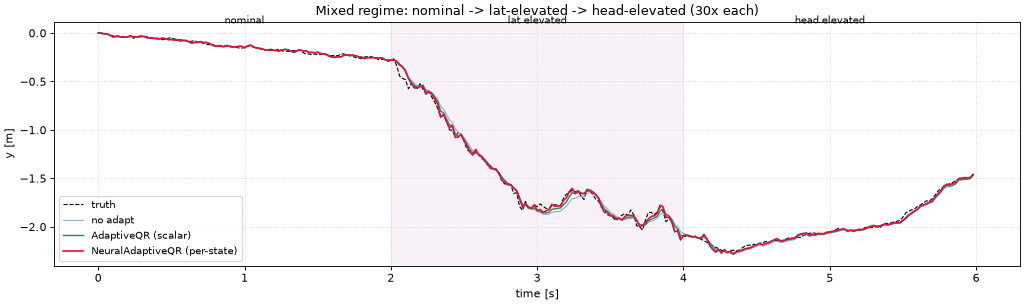

Controller                  RMSE   vs no-adapt   vs AdaptiveQR
--------------------------------------------------------------
No adapt                   0.037      baseline                
AdaptiveQR (scalar)        0.028           23%        baseline
NeuralAdaptiveQR           0.025           32%             12%

predicted regime in each true segment (from step 20 of the segment on, when the window is full):
  true=nominal  predicted: Counter({'nominal': 74, 'head': 6})
  true=lat      predicted: Counter({'lat': 68, 'nominal': 9, 'head': 3})
  true=head     predicted: Counter({'nominal': 47, 'head': 33})


In [16]:
nqr = NeuralAdaptiveQRKalmanController(
    lane_model(),
    window=20, hidden=16,
)
nqr.fit(
    regime_scales={"nominal": [1.0, 1.0, 1.0], "lat": [30.0, 1.0, 1.0], "head": [1.0, 30.0, 1.0]},
    n_episodes=450, episode_len=60, epochs=150, lr=2e-3, seed=1,
)

def sim_mixed(seed=7, seg=100, factor=30):
    """100 steps nominal, 100 lat-elevated, 100 head-elevated -- one continuous run."""
    rng = np.random.default_rng(seed)
    y, psi, v = 0.0, 0.0, 15.0
    regimes = ["nominal", "lat", "head"]
    N_ = seg * 3
    zk_ = np.zeros((N_, 1)); truth_ = np.zeros(N_); labels_ = []
    for k in range(N_):
        r = regimes[k // seg]
        labels_.append(r)
        truth_[k] = y
        zk_[k, 0] = y + rng.normal(0, LATERAL_NOISE_STD)
        q_lat = q_lat0 * (factor if r == "lat" else 1.0)
        q_head = q_head0 * (factor if r == "head" else 1.0)
        y = y + v * np.sin(psi) / 50 + rng.normal(0, np.sqrt(q_lat))
        psi = psi + rng.normal(0, np.sqrt(q_head))
        v = v + rng.normal(0, np.sqrt(q_vel0))
    return zk_, truth_, labels_

zk_mix, truth_mix, labels_mix = sim_mixed()
t_mix = np.arange(len(zk_mix)) / 50

est_no_mix = np.asarray(ExtendedKalmanFilter(lane_model()).forward(zk_mix).xk)[:, 0]

model_aq_mix = lane_model()
aqr_mix = AdaptiveQRKalmanController(model_aq_mix, window=20, q_min=0.5, q_max=10.0)
est_aq_mix = np.asarray(ExtendedKalmanFilter(model_aq_mix).forward(zk_mix, uk=aqr_mix).xk)[:, 0]

model_nq_mix = lane_model()
nqr_mix = NeuralAdaptiveQRKalmanController(model_nq_mix, window=20, hidden=16)
nqr_mix._model_nn = nqr._model_nn
nqr_mix._x_mean, nqr_mix._x_std = nqr._x_mean, nqr._x_std
nqr_mix.regime_scales, nqr_mix._labels = nqr.regime_scales, nqr._labels
est_nq_mix = np.asarray(ExtendedKalmanFilter(model_nq_mix).forward(zk_mix, uk=nqr_mix).xk)[:, 0]

rmse_no_mix = np.sqrt(np.mean((est_no_mix - truth_mix) ** 2))
rmse_aq_mix = np.sqrt(np.mean((est_aq_mix - truth_mix) ** 2))
rmse_nq_mix = np.sqrt(np.mean((est_nq_mix - truth_mix) ** 2))

fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(t_mix, truth_mix, color="black", lw=1, ls="--", label="truth")
ax.plot(t_mix, est_no_mix, color="steelblue", lw=1, alpha=0.6, label="no adapt")
ax.plot(t_mix, est_aq_mix, color="seagreen", lw=1.3, label="AdaptiveQR (scalar)")
ax.plot(t_mix, est_nq_mix, color="crimson", lw=1.5, label="NeuralAdaptiveQR (per-state)")
for k, seg_lbl in enumerate(["nominal", "lat elevated", "head elevated"]):
    ax.axvspan(k * 2.0, (k + 1) * 2.0, alpha=0.05, color="purple" if k % 2 else "none")
    ax.text(k * 2.0 + 1.0, ax.get_ylim()[1] * 0.85, seg_lbl, ha="center", fontsize=9)
ax.set_xlabel("time [s]"); ax.set_ylabel("y [m]")
ax.set_title("Mixed regime: nominal -> lat-elevated -> head-elevated (30x each)")
ax.legend(fontsize=9, loc="lower left"); ax.grid(True, ls=":", alpha=0.5)
plt.tight_layout(); plt.show()

print(f"{'Controller':<24}{'RMSE':>8}{'vs no-adapt':>14}{'vs AdaptiveQR':>16}")
print("-" * 62)
print(f"{'No adapt':<24}{rmse_no_mix:>8.3f}{'baseline':>14}{'':>16}")
print(f"{'AdaptiveQR (scalar)':<24}{rmse_aq_mix:>8.3f}{(1-rmse_aq_mix/rmse_no_mix)*100:>13.0f}%{'baseline':>16}")
print(f"{'NeuralAdaptiveQR':<24}{rmse_nq_mix:>8.3f}{(1-rmse_nq_mix/rmse_no_mix)*100:>13.0f}%"
      f"{(1-rmse_nq_mix/rmse_aq_mix)*100:>15.0f}%")

from collections import Counter
preds_mix = [lbl for _, _, lbl in nqr_mix.scale_log]
n_each = len(preds_mix) // 3 if len(preds_mix) >= 3 else len(preds_mix)
print()
print("predicted regime in each true segment (from step 20 of the segment on, when the window is full):")
for name, sl in [("nominal", slice(0, 80)), ("lat", slice(100, 180)), ("head", slice(200, 280))]:
    print(f"  true={name:<8} predicted:", Counter(preds_mix[sl]))

The classifier recognises the nominal and the lateral segments most of the time, but the heading segment less than half of the time: the heading noise is hard to see in 20 innovations, even for a classifier built for it. Over the whole run it still lowers the error more than the scalar rule.

## 8 — Interactive Kalman Filter: Switching Between Models

A system can switch between regimes, for example a dry road and an icy one. The **Interactive Kalman Filter** (IKF), which the literature calls the Interacting Multiple Model (IMM) filter, runs one filter per regime. At each step it:

1. mixes the regime estimates according to a Markov transition matrix (the probability of switching regime in one step);
2. predicts and updates each filter;
3. scores each filter by the likelihood of its innovation;
4. updates the **mode probabilities** $\mu$ with Bayes' rule;
5. combines the estimates, $\hat{\mathbf{x}} = \sum_j \mu_j \hat{\mathbf{x}}_j$.

Here the icy road has a lateral process noise of 5 cm per step instead of 1 cm, as the car slips. The road turns icy after 3 s.

steps where the more probable regime is the true one: 81%


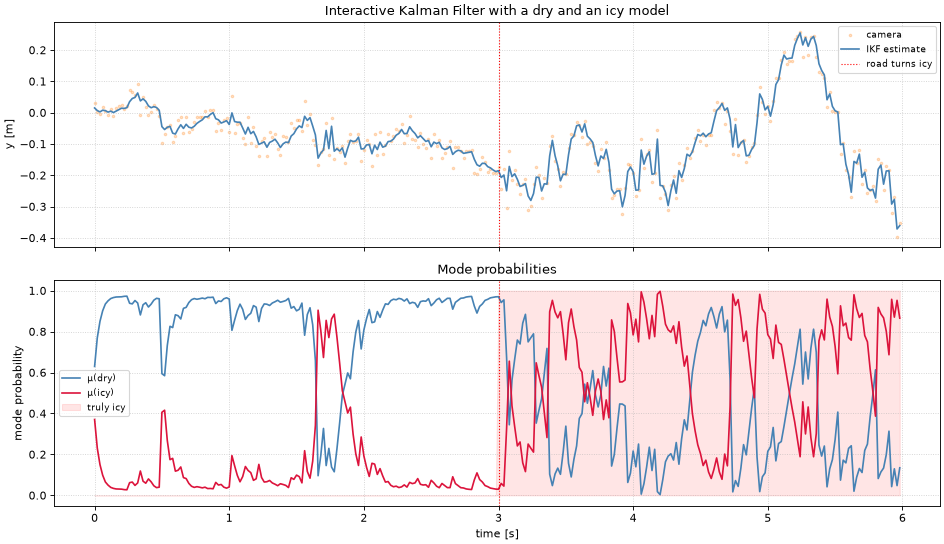

In [17]:
from kalman.framework.filters import InteractiveKalmanFilter

# Process-noise variances per step: dry (1 cm)² and (1 mrad)², icy (5 cm)² and (10 mrad)²
model_normal = CarLaneModel("road", fs=50, lateral_uncertainty=LATERAL_NOISE_STD, q_lat=1e-4, q_head=1e-6)
model_icy = CarLaneModel("ice", fs=50, lateral_uncertainty=LATERAL_NOISE_STD, q_lat=2.5e-3, q_head=1e-4)

# Transition matrix per step: dry stays dry with 98%, icy stays icy with 95%
Pi = np.array([
    [0.98, 0.02],
    [0.05, 0.95],
])

ikf = InteractiveKalmanFilter([model_normal, model_icy], transition=Pi)

# Truth: dry for 150 steps, icy for the next 150
N_imm = 300
zk_imm = np.zeros((N_imm, 1))
regime_true = np.zeros(N_imm)
y_true_imm = 0.0
for k in range(N_imm):
    if k < 150:
        y_true_imm += np.random.normal(0, 0.01)
        regime_true[k] = 0
    else:
        y_true_imm += np.random.normal(0, 0.05)
        regime_true[k] = 1
    zk_imm[k] = y_true_imm + np.random.normal(0, LATERAL_NOISE_STD)

rec_imm = ikf.forward(zk_imm)
mu = ikf.mode_probabilities
print(f"steps where the more probable regime is the true one: {np.mean((mu[:, 1] > 0.5) == regime_true):.0%}")

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
t_imm = np.arange(N_imm) * dt

axes[0].scatter(t_imm, zk_imm, s=5, alpha=0.25, color="tab:orange", label="camera")
axes[0].plot(t_imm, np.asarray(rec_imm.xk)[:, 0], color="steelblue", lw=1.5, label="IKF estimate")
axes[0].axvline(3.0, color="red", ls=":", lw=1, label="road turns icy")
axes[0].set_ylabel("y [m]")
axes[0].set_title("Interactive Kalman Filter with a dry and an icy model")
axes[0].legend(fontsize=8); axes[0].grid(True, ls=":", alpha=0.6)

axes[1].plot(t_imm, mu[:, 0], color="steelblue", lw=1.5, label="μ(dry)")
axes[1].plot(t_imm, mu[:, 1], color="crimson", lw=1.5, label="μ(icy)")
axes[1].fill_between(t_imm, 0, regime_true, alpha=0.1, color="red", label="truly icy")
axes[1].axvline(3.0, color="red", ls=":", lw=1)
axes[1].set_xlabel("time [s]"); axes[1].set_ylabel("mode probability")
axes[1].set_title("Mode probabilities")
axes[1].legend(fontsize=8); axes[1].grid(True, ls=":", alpha=0.6)

plt.tight_layout(); plt.show()

Before the switch the dry model dominates, apart from one short false alarm. After it the icy model is the more probable one most of the time, but its probability swings strongly: a random step of 5 cm standard deviation is often small enough to look like a dry-road step. The IKF needs several steps of evidence, and the evidence keeps changing.

## 9 — Routers: How the IKF Weighs Its Models

The IKF's mode probabilities come from a **router**. The default `BayesianRouter` weighs model $j$ by its Gaussian innovation likelihood $L_j = \mathcal{N}(\nu_j; 0, \mathbf{S}_j)$ times its prior probability $c_j$ from the transition matrix. This is optimal when every model is correct and the noise is Gaussian. Any other router can be plugged in:

```
ikf = InteractiveKalmanFilter(models, Pi, router=BayesianRouter())              # default
ikf = InteractiveKalmanFilter(models, Pi, router=ThresholdRouter())             # rule on the recent NIS
ikf = InteractiveKalmanFilter(models, Pi, router=NeuralRouter(model=MLP()))     # learned
ikf = InteractiveKalmanFilter(models, Pi, router=HybridRouter(r_a, r_b, alpha)) # blend of two routers
```

`ThresholdRouter` and `NeuralRouter` look at the NIS of each model over the last few steps. Under the correct model the NIS averages $m$ (here 1); under a model with too little process noise it is much larger, and under one with too much it is smaller. The NIS is a convenient input for a network because it has no units and does not depend on which router produced the earlier mode probabilities.

The test uses two 1-D random walks with the same measurement noise (standard deviation 1) and process noise of standard deviation 0.1 ("smooth") or 2 ("rough"). The neural routers are trained on three labelled sequences.

fraction of steps where the more probable model is the true one:
  BayesianRouter           94.0%
  ThresholdRouter          90.5%
  NeuralRouter             84.0%
  HybridRouter (α=0.5)     87.0%


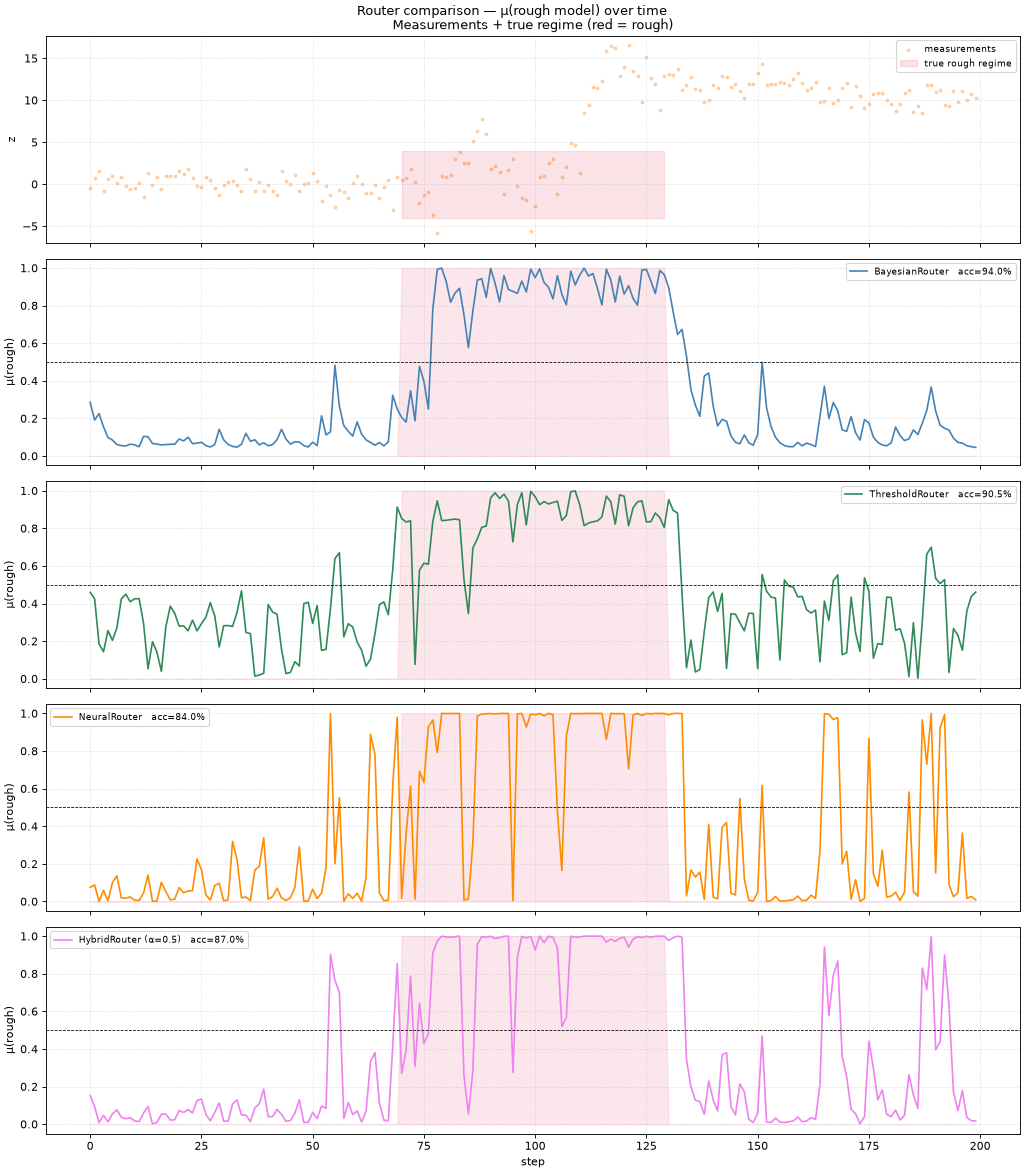

In [18]:
from kalman.framework.filters import InteractiveKalmanFilter
from kalman.framework.routers import BayesianRouter, ThresholdRouter, NeuralRouter, HybridRouter
from kalman.framework.routers.nn import MLP
from kalman.framework.model import KalmanModel

# Two 1-D random-walk models: process noise std 0.1 (smooth) or 2.0 (rough), measurement noise std 1.0

def _make_models():
    m0 = KalmanModel('smooth', F=np.eye(1), H=np.eye(1),
                     Q=np.array([[0.1**2]]), R=np.array([[1.0**2]]),
                     fs=1.0, x0=np.array([[0.0]]))
    m1 = KalmanModel('rough', F=np.eye(1), H=np.eye(1),
                     Q=np.array([[2.0**2]]), R=np.array([[1.0**2]]),
                     fs=1.0, x0=np.array([[0.0]]))
    return m0, m1

Pi_r = np.array([[0.95, 0.05], [0.05, 0.95]])

def sim_switching(regime_seq, seed=None):
    rng = np.random.default_rng(seed)
    x, zk, labels = 0.0, [], []
    for r in regime_seq:
        x += rng.normal(0, 0.1 if r == 0 else 2.0)
        zk.append([x + rng.normal(0, 1.0)]); labels.append(r)
    return np.array(zk), np.array(labels)

T = 200

# ── Training scenarios (3 × 200 steps) ──────────────────────────────────────
regimes_train = [
    np.r_[np.zeros(100,int), np.ones(100,int)],
    np.r_[np.ones(50,int), np.zeros(100,int), np.ones(50,int)],
    np.r_[np.zeros(60,int), np.ones(80,int), np.zeros(60,int)],
]
train_zk, train_lbl = [], []
for rs in regimes_train:
    z, l = sim_switching(rs, seed=len(train_zk)); train_zk.append(z); train_lbl.append(l)

# ── Test: 0 → 1 → 0 ─────────────────────────────────────────────────────────
r_test = np.r_[np.zeros(70,int), np.ones(60,int), np.zeros(70,int)]
zk_test, lbl_test = sim_switching(r_test, seed=99)

# ── Run each router ──────────────────────────────────────────────────────────
neural_router = NeuralRouter(model=MLP(hidden=16), window=5)

routers = {
    "BayesianRouter":         BayesianRouter(),
    "ThresholdRouter":        ThresholdRouter(m=1, window=5, soft=True),
    "NeuralRouter":           neural_router,
    "HybridRouter (α=0.5)":   HybridRouter(BayesianRouter(), neural_router, alpha=0.5),
}

mu_results, acc_results = {}, {}
for name, router in routers.items():
    m0, m1 = _make_models()
    ikf = InteractiveKalmanFilter([m0, m1], Pi_r, router=router)
    if name in ("NeuralRouter", "HybridRouter (α=0.5)"):
        ikf.fit(train_zk, train_lbl, epochs=500, lr=2e-3, seed=7)
    ikf.forward(zk_test)
    mu_results[name] = ikf.mode_probabilities
    acc_results[name] = float((np.argmax(ikf.mode_probabilities,1) == lbl_test).mean())

print("fraction of steps where the more probable model is the true one:")
for name, acc in acc_results.items():
    print(f"  {name:<24} {acc*100:.1f}%")

# ── Plot comparison ───────────────────────────────────────────────────────────
t_nim = np.arange(T)
colors = {"BayesianRouter": "steelblue", "ThresholdRouter": "seagreen",
          "NeuralRouter": "darkorange", "HybridRouter (α=0.5)": "violet"}

fig, axes = plt.subplots(len(routers) + 1, 1, figsize=(13, 3*(len(routers)+1)), sharex=True)

axes[0].scatter(t_nim, zk_test, s=6, alpha=0.3, color="tab:orange", label="measurements")
axes[0].fill_between(t_nim, -4, 4, where=(lbl_test==1), alpha=0.12,
                     color="crimson", label="true rough regime")
axes[0].set_ylabel("z"); axes[0].set_title("Measurements + true regime (red = rough)")
axes[0].legend(fontsize=8); axes[0].grid(True, ls=":", alpha=0.5)

for ax, (name, mu) in zip(axes[1:], mu_results.items()):
    ax.plot(t_nim, mu[:, 1], color=colors[name], lw=1.5,
            label=f"{name}   acc={acc_results[name]*100:.1f}%")
    ax.fill_between(t_nim, 0, lbl_test, alpha=0.1, color="crimson")
    ax.axhline(0.5, color="black", ls="--", lw=0.7)
    ax.set_ylim(-0.05, 1.05); ax.set_ylabel("μ(rough)")
    ax.legend(fontsize=8); ax.grid(True, ls=":", alpha=0.5)

axes[-1].set_xlabel("step")
plt.suptitle("Router comparison — μ(rough model) over time", fontsize=12)
plt.tight_layout(); plt.show()

With Gaussian noise the Bayesian router is the most accurate, as it should be. The neural router, trained on only three sequences, is the least accurate, and the hybrid lies in between.

## 10 — When Gaussian Likelihoods Get It Wrong

Real noise is often **heavy-tailed**: large values occur far more often than a Gaussian allows. The Gaussian likelihood falls off as $e^{-\nu^2/2S}$, so a single large innovation can change the ratio of two likelihoods by orders of magnitude, and the Bayesian router flips its choice on one outlier although the regime has not changed.

The benchmark alternates between two regimes of a 1-D random walk:

| | regime A | regime B |
|---|---|---|
| process noise | Gaussian, variance 0.1 | Student-t with 3 degrees of freedom, variance 2.0 |
| filter for it | model A, $\mathbf{Q} = 0.1$ | model B, $\mathbf{Q} = 2.0$: the right variance, the wrong shape |

Besides the accuracy, we count **spurious switches**: steps where the router's choice flips inside a segment where the true regime did not change. We compare the neural routers with the Bayesian router and also with `ThresholdRouter`, which averages the NIS over a window without any training. The second comparison says whether the network earns its training.

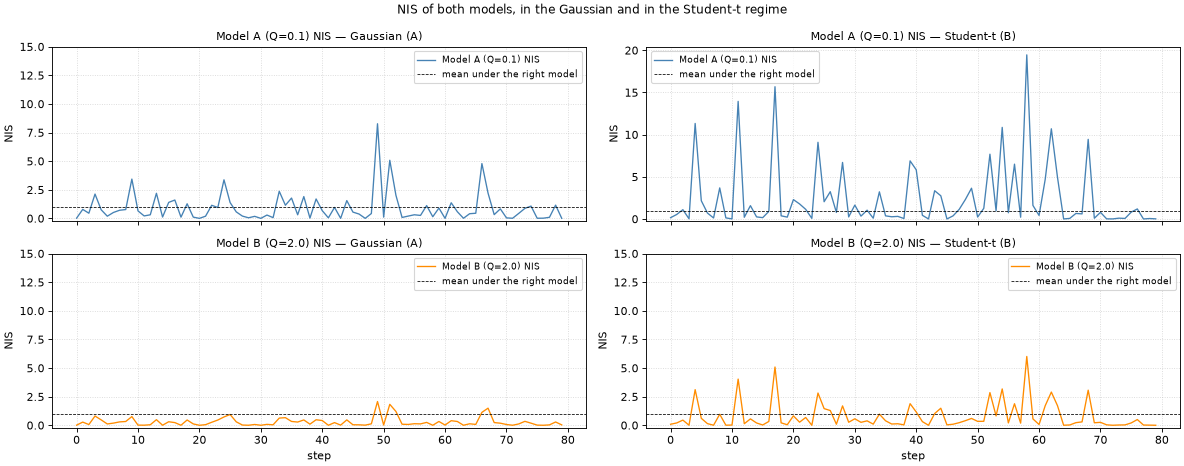

NIS mean and innovation excess kurtosis, per regime and model:
  Gaussian (A)   model A: mean NIS 0.91   excess kurtosis +0.0
  Gaussian (A)   model B: mean NIS 0.29   excess kurtosis -0.1
  Student-t (B)  model A: mean NIS 2.48   excess kurtosis +0.5
  Student-t (B)  model B: mean NIS 0.79   excess kurtosis +0.3


In [19]:
import time
from kalman.framework.filter import KalmanFilter
from kalman.framework.routers import BayesianRouter, ThresholdRouter, NeuralRouter
from kalman.framework.routers.nn import MLP, CNN, LSTM, TransformerNN

np.random.seed(42)

# ── Parameters ────────────────────────────────────────────────────────────────
Q_A   = 0.1      # process-noise variance, Gaussian regime
Q_B   = 2.0      # process-noise variance, Student-t regime (DF = 3 degrees of freedom)
R_OBS = 0.5      # measurement-noise variance (both models)
WINDOW = 15      # number of past NIS values the neural routers see

# ── Models & IKF factory ──────────────────────────────────────────────────────
def _make_models():
    kf_a = KalmanFilter(n=1, m=1,
                        F=np.array([[1.]]), H=np.array([[1.]]),
                        Q=np.array([[Q_A]]), R=np.array([[R_OBS]]),
                        x0=np.zeros((1, 1)), P0=2 * np.eye(1))
    kf_b = KalmanFilter(n=1, m=1,
                        F=np.array([[1.]]), H=np.array([[1.]]),
                        Q=np.array([[Q_B]]), R=np.array([[R_OBS]]),
                        x0=np.zeros((1, 1)), P0=2 * np.eye(1))
    return [kf_a._model, kf_b._model]

Pi = np.array([[0.85, 0.15], [0.15, 0.85]])

def make_ikf(router=None):
    return InteractiveKalmanFilter(_make_models(), Pi, router=router)

# ── Data generation ───────────────────────────────────────────────────────────
def gen_segment(regime, T, rng=None, x0=0.0, return_truth=False):
    """Regime 0: Gaussian process noise.  Regime 1: Student-t noise of variance Q_B."""
    rng = rng or np.random.default_rng()
    x, zk, xs = x0, [], []
    for k in range(T):
        if regime == 0:
            w = rng.normal(0, Q_A ** .5)
        else:
            scale = (Q_B * (DF - 2) / DF) ** .5
            w = float(t_dist.rvs(DF, scale=scale, random_state=rng))
        x += w
        xs.append(x)
        zk.append([x + rng.normal(0, R_OBS ** .5)])
    out = (np.array(zk), np.full(T, regime, dtype=int))
    return out + (np.array(xs),) if return_truth else out

def gen_switching(T, seg_len, seed=None, return_truth=False):
    """Alternating segments A, B, A, ... The true state starts again at 0 in every segment."""
    rng = np.random.default_rng(seed)
    zparts, lparts, xparts = [], [], []
    for s in range(T // seg_len):
        z, l, x = gen_segment(s % 2, seg_len, rng=rng, return_truth=True)
        zparts.append(z); lparts.append(l); xparts.append(x)
    out = (np.concatenate(zparts), np.concatenate(lparts))
    return out + (np.concatenate(xparts),) if return_truth else out

# ── Part 1 — the NIS of both models in each regime ───────────────────────────
T_vis = 80
zk_A, _ = gen_segment(0, T_vis, rng=np.random.default_rng(7))
zk_B, _ = gen_segment(1, T_vis, rng=np.random.default_rng(7))

nis_per_regime = {}
for label, zk in [("Gaussian (A)", zk_A), ("Student-t (B)", zk_B)]:
    ikf_v = make_ikf(); ikf_v.forward(zk)
    nis_per_regime[label] = np.array(ikf_v.nis_log)

fig, axes = plt.subplots(2, 2, figsize=(15, 6), sharex=True)
sp = np.arange(T_vis)

for col, label in enumerate(["Gaussian (A)", "Student-t (B)"]):
    nis = nis_per_regime[label]
    for row, (mid, color, mname) in enumerate([(0, "steelblue", "Model A (Q=0.1)"),
                                                (1, "darkorange", "Model B (Q=2.0)")]):
        ax = axes[row, col]
        ax.plot(sp, nis[:, mid], color=color, lw=1.2, label=f"{mname} NIS")
        ax.axhline(1.0, color="black", ls="--", lw=0.7, label="mean under the right model")
        ax.set_title(f"{mname} NIS — {label}", fontsize=10)
        ax.set_ylabel("NIS")
        ax.set_ylim(-0.2, max(15, nis[:, mid].max() * 1.05))
        ax.legend(fontsize=8); ax.grid(True, ls=":", alpha=0.5)
        if row == 1:
            ax.set_xlabel("step")

fig.suptitle("NIS of both models, in the Gaussian and in the Student-t regime", fontsize=11)
plt.tight_layout(); plt.show()

# The NIS is the squared normalised innovation, so mean(NIS²)/mean(NIS)² - 3 is the excess
# kurtosis of the innovation itself: 0 for Gaussian innovations, larger for heavy tails.
print("NIS mean and innovation excess kurtosis, per regime and model:")
for label in ["Gaussian (A)", "Student-t (B)"]:
    nis = nis_per_regime[label]
    for j, mname in enumerate(["model A", "model B"]):
        v = nis[:, j]
        kurt = float(np.mean(v ** 2) / np.mean(v) ** 2 - 3)
        print(f"  {label:<14} {mname}: mean NIS {v.mean():.2f}   excess kurtosis {kurt:+.1f}")

The regimes differ mostly in the size of the NIS: in regime B the mean NIS of model A is nearly three times larger than in regime A. Over 80 steps the heavy tails hardly show in the kurtosis of the innovations; they appear as a few isolated spikes in the NIS plot. Those spikes are what a router reacting to one step at a time trips over.

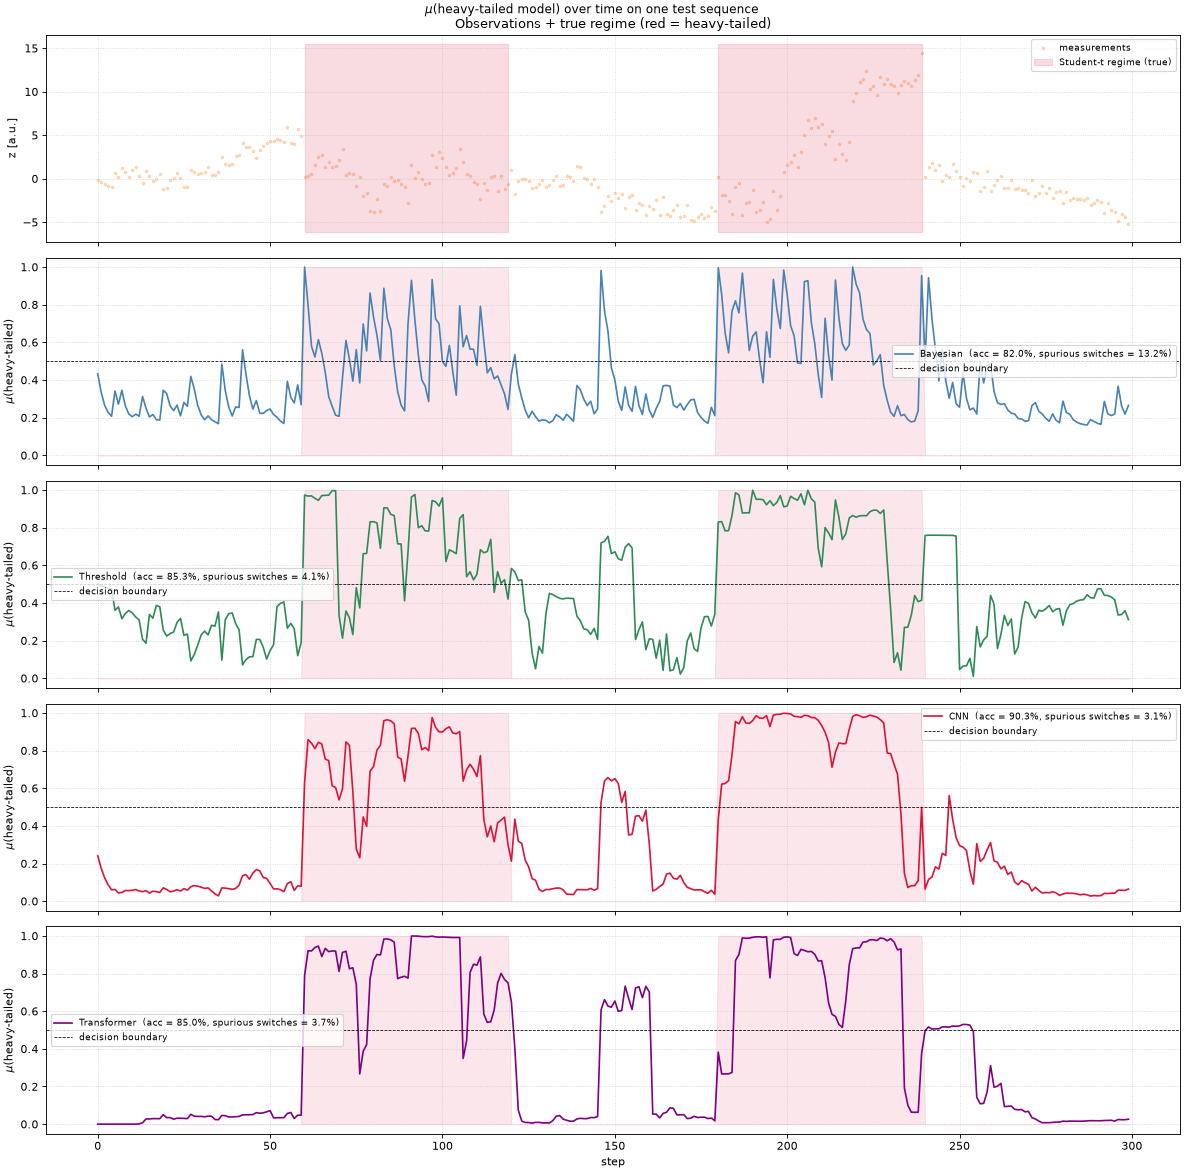

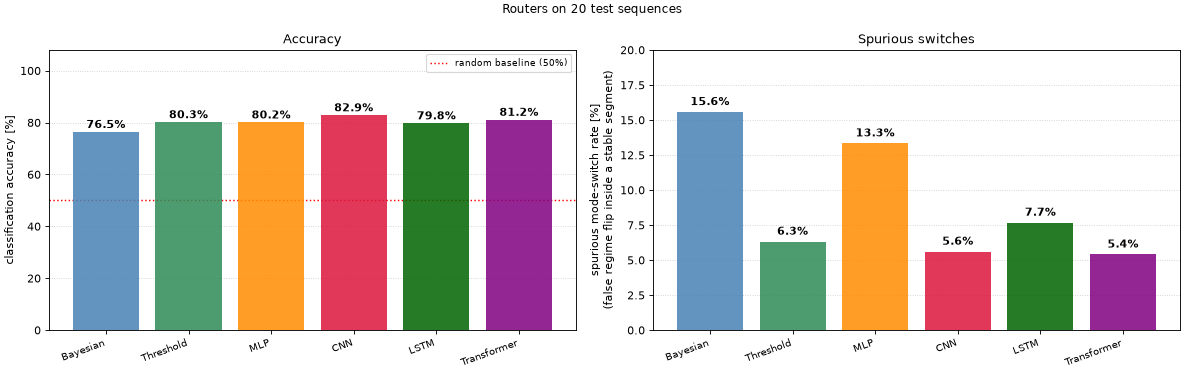

router           accuracy   vs Bayes  vs Thresh    spurious   vs Bayes  vs Thresh
------------------------------------------------------------------------------------------
Bayesian            76.5%   baseline    -3.8 pp       15.6%   baseline    +9.3 pp
Threshold           80.3%    +3.8 pp   baseline        6.3%    -9.3 pp   baseline
MLP                 80.2%    +3.7 pp    -0.1 pp       13.3%    -2.2 pp    +7.0 pp
CNN                 82.9%    +6.4 pp    +2.7 pp        5.6%   -10.0 pp    -0.7 pp
LSTM                79.8%    +3.3 pp    -0.4 pp        7.7%    -7.9 pp    +1.4 pp
Transformer         81.2%    +4.7 pp    +0.9 pp        5.4%   -10.2 pp    -0.9 pp


In [20]:
# ── Part 2 — train the routers on 16 labelled sequences of 400 steps ─────────
train_zk, train_lbl = [], []
for i in range(16):
    z, l = gen_switching(400, 80, seed=i)
    train_zk.append(z); train_lbl.append(l)

all_routers = {
    "Bayesian":   BayesianRouter(),
    "Threshold":  ThresholdRouter(m=1, window=10, soft=True),
}

neural_specs = [
    ("MLP",         MLP(hidden=48),                     dict(epochs=200, lr=2e-3, seed=0)),
    ("CNN",         CNN(out_channels=16, kernel_size=4), dict(epochs=200, lr=3e-3, seed=1)),
    ("LSTM",        LSTM(hidden=24),                    dict(epochs=300, lr=1e-3, seed=2)),
    ("Transformer", TransformerNN(d_model=16),          dict(epochs=200, lr=2e-3, seed=3)),
]

for name, arch, kw in neural_specs:
    router = NeuralRouter(model=arch, window=WINDOW)
    ikf_tr = make_ikf(router=router)
    cached_fit(CACHE / f"router_{name}.pt",
               lambda ikf_tr=ikf_tr: ikf_tr.fit(train_zk, train_lbl, **kw),
               load=router.load, save=router.save, verbose=False)
    all_routers[name] = router

# ── Part 3 — accuracy and spurious-switch rate on 20 new sequences ───────────
def chatter_rate(mu_arr, labels):
    """Fraction of steps inside a constant-regime segment where argmax(mu) flips anyway."""
    preds = np.argmax(mu_arr, axis=1)
    flips = (preds[1:] != preds[:-1])
    same_truth = (labels[1:] == labels[:-1])
    return float((flips & same_truth).sum() / same_truth.sum())

def evaluate(router, n_seqs=20, seed_base=500):
    accs, chatters = [], []
    for i in range(n_seqs):
        z, l = gen_switching(300, 60, seed=seed_base + i)
        ikf_e = make_ikf(router=router)
        ikf_e.forward(z)
        mu = np.array(ikf_e.mu_log)
        accs.append((np.argmax(mu, axis=1) == l).mean())
        chatters.append(chatter_rate(mu, l))
    return float(np.mean(accs)), float(np.mean(chatters))

results = {name: evaluate(r) for name, r in all_routers.items()}
acc_bay, ch_bay = results["Bayesian"]
acc_thr, ch_thr = results["Threshold"]

# ── Part 4 — μ trajectory comparison ─────────────────────────────────────────
z_test, l_test = gen_switching(300, 60, seed=999)
show_routers = ["Bayesian", "Threshold", "CNN", "Transformer"]
colors_map = {"Bayesian": "steelblue", "Threshold": "seagreen",
              "CNN": "crimson", "Transformer": "purple"}

mu_traces = {}
for rname in show_routers:
    ikf_t = make_ikf(router=all_routers[rname])
    ikf_t.forward(z_test)
    mu_traces[rname] = np.array(ikf_t.mu_log)

fig, axes = plt.subplots(len(show_routers) + 1, 1,
                          figsize=(15, 3 * (len(show_routers) + 1)), sharex=True)
t_sp = np.arange(len(z_test))

axes[0].scatter(t_sp, z_test, s=5, alpha=0.25, color="tab:orange", label="measurements")
axes[0].fill_between(t_sp, z_test.min() - 1, z_test.max() + 1,
                     where=(l_test == 1), alpha=0.15, color="crimson",
                     label="Student-t regime (true)")
axes[0].set_ylabel("z [a.u.]")
axes[0].set_title("Observations + true regime (red = heavy-tailed)")
axes[0].legend(fontsize=8); axes[0].grid(True, ls=":", alpha=0.5)

for ax, rname in zip(axes[1:], show_routers):
    mu = mu_traces[rname]
    acc_test = float((np.argmax(mu, axis=1) == l_test).mean())
    ch_test = chatter_rate(mu, l_test)
    ax.plot(t_sp, mu[:, 1], color=colors_map[rname], lw=1.5,
            label=f"{rname}  (acc = {acc_test:.1%}, spurious switches = {ch_test:.1%})")
    ax.fill_between(t_sp, 0, l_test, alpha=0.10, color="crimson")
    ax.axhline(0.5, color="black", ls="--", lw=0.7, label="decision boundary")
    ax.set_ylim(-0.05, 1.05); ax.set_ylabel("$\\mu$(heavy-tailed)")
    ax.legend(fontsize=8); ax.grid(True, ls=":", alpha=0.5)

axes[-1].set_xlabel("step")
fig.suptitle("$\\mu$(heavy-tailed model) over time on one test sequence", fontsize=11)
plt.tight_layout(); plt.show()

# ── Part 5 — accuracy AND chatter-rate bar charts, side by side ──────────────
bar_colors = ["steelblue", "seagreen", "darkorange", "crimson", "darkgreen", "purple"]
names = list(results.keys())
accs  = [results[n][0] * 100 for n in names]
chs   = [results[n][1] * 100 for n in names]

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

bars0 = axes[0].bar(names, accs, color=bar_colors[:len(names)], alpha=0.85, zorder=3)
for bar, a in zip(bars0, accs):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.4,
                f"{a:.1f}%", ha="center", va="bottom", fontsize=10, fontweight="bold")
axes[0].axhline(50, color="red", ls=":", lw=1.3, label="random baseline (50%)")
axes[0].set_ylabel("classification accuracy [%]")
axes[0].set_title("Accuracy")
axes[0].set_xticklabels(names, rotation=20, ha="right", fontsize=9)
axes[0].set_ylim(0, 108); axes[0].legend(fontsize=8)
axes[0].grid(True, axis="y", ls=":", alpha=0.6, zorder=0)

bars1 = axes[1].bar(names, chs, color=bar_colors[:len(names)], alpha=0.85, zorder=3)
for bar, c in zip(bars1, chs):
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
                f"{c:.1f}%", ha="center", va="bottom", fontsize=10, fontweight="bold")
axes[1].set_ylabel("spurious mode-switch rate [%]\n(false regime flip inside a stable segment)")
axes[1].set_title("Spurious switches")
axes[1].set_xticklabels(names, rotation=20, ha="right", fontsize=9)
axes[1].grid(True, axis="y", ls=":", alpha=0.6, zorder=0)
axes[1].set_ylim(0,20)

fig.suptitle("Routers on 20 test sequences", fontsize=11)
plt.tight_layout(); plt.show()

print(f"{'router':<14} {'accuracy':>10} {'vs Bayes':>10} {'vs Thresh':>10}   {'spurious':>9} {'vs Bayes':>10} {'vs Thresh':>10}")
print("-" * 90)
for name, (acc, ch) in results.items():
    da_b = "baseline" if name == "Bayesian" else f"{(acc-acc_bay)*100:+.1f} pp"
    da_t = "baseline" if name == "Threshold" else f"{(acc-acc_thr)*100:+.1f} pp"
    dc_b = "baseline" if name == "Bayesian" else f"{(ch-ch_bay)*100:+.1f} pp"
    dc_t = "baseline" if name == "Threshold" else f"{(ch-ch_thr)*100:+.1f} pp"
    print(f"{name:<14} {acc:>10.1%} {da_b:>10} {da_t:>10}   {ch:>9.1%} {dc_b:>10} {dc_t:>10}")

The Bayesian router switches spuriously on about one step in six, two to three times as often as the threshold, CNN, LSTM and Transformer routers. Most of that improvement comes from looking at a window of NIS values: the untrained threshold router gets most of it. The best networks add up to 3 points of accuracy on top; the MLP gains in accuracy but not in steadiness.

### Watching the Routers Learn

The loss curves below show how each network's training error fell, epoch by epoch. A lower final loss does not mean a better router on new data; compare with the test numbers above.

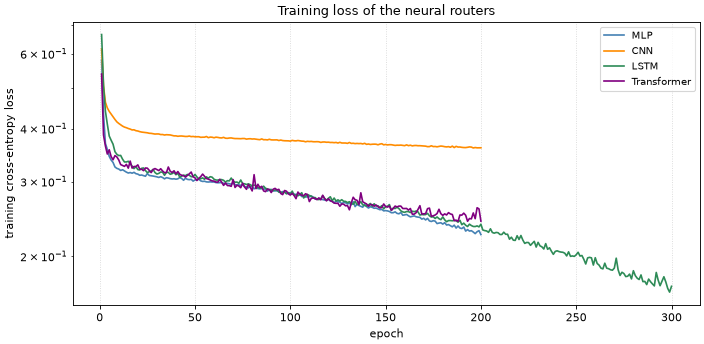

MLP          epoch 1: 0.580   epoch 50: 0.303   final: 0.225
CNN          epoch 1: 0.616   epoch 50: 0.383   final: 0.361
LSTM         epoch 1: 0.666   epoch 75: 0.297   final: 0.170
Transformer  epoch 1: 0.538   epoch 50: 0.306   final: 0.242


In [21]:
fig, ax = plt.subplots(figsize=(9, 4.5))
loss_colors = {"MLP": "steelblue", "CNN": "darkorange", "LSTM": "seagreen", "Transformer": "purple"}
for name in ["MLP", "CNN", "LSTM", "Transformer"]:
    hist = all_routers[name].model.loss_history
    ax.plot(np.arange(1, len(hist) + 1), hist, color=loss_colors[name], lw=1.5, label=name)
ax.set_xlabel("epoch"); ax.set_ylabel("training cross-entropy loss")
ax.set_title("Training loss of the neural routers")
ax.legend(fontsize=9); ax.grid(True, ls=":", alpha=0.5)
ax.set_yscale("log")
plt.tight_layout(); plt.show()

for name in ["MLP", "CNN", "LSTM", "Transformer"]:
    hist = all_routers[name].model.loss_history
    print(f"{name:<12} epoch 1: {hist[0]:.3f}   epoch {len(hist)//4}: {hist[len(hist)//4 - 1]:.3f}   "
          f"final: {hist[-1]:.3f}")

What does the network learn? We hold model A's NIS at 1 (what the right model gives on average), sweep model B's NIS from 0.1 to 6, and read the CNN's probability for regime B. We do this for a fresh CNN after 0, 1, 2, 3, 5 and 10 training epochs.

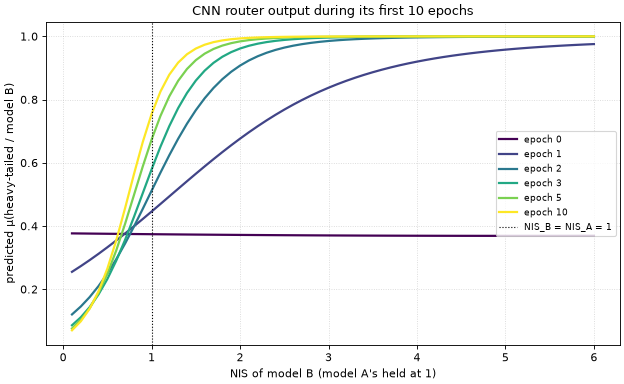

epoch  0: P(regime B) at NIS_B = 0.5: 0.38,  at NIS_B = 1: 0.37,  at NIS_B = 4: 0.37
epoch  1: P(regime B) at NIS_B = 0.5: 0.33,  at NIS_B = 1: 0.45,  at NIS_B = 4: 0.92
epoch  2: P(regime B) at NIS_B = 0.5: 0.25,  at NIS_B = 1: 0.51,  at NIS_B = 4: 1.00
epoch  3: P(regime B) at NIS_B = 0.5: 0.23,  at NIS_B = 1: 0.58,  at NIS_B = 4: 1.00
epoch  5: P(regime B) at NIS_B = 0.5: 0.25,  at NIS_B = 1: 0.67,  at NIS_B = 4: 1.00
epoch 10: P(regime B) at NIS_B = 0.5: 0.27,  at NIS_B = 1: 0.75,  at NIS_B = 4: 1.00


In [22]:
from kalman.framework.routers.nn import CNN as _CNN_watch

# The training inputs: windows of NIS values from the training sequences, with their labels.
nis_arrays_w, label_arrays_w = [], []
for zk_w, labels_w in zip(train_zk, train_lbl):
    ikf_w = make_ikf(router=BayesianRouter())
    ikf_w.forward(zk_w, record=False)
    nis_arrays_w.append(np.array(ikf_w.nis_log))
    label_arrays_w.append(np.asarray(labels_w, dtype=int))

probe_router = NeuralRouter(model=None, window=WINDOW)
X_w, y_w = [], []
for nis_arr, labels_w in zip(nis_arrays_w, label_arrays_w):
    for k, lbl in enumerate(labels_w):
        X_w.append(probe_router._window_feat(nis_arr[:k + 1]))
        y_w.append(int(lbl))
X_w = np.array(X_w, dtype=np.float32); y_w = np.array(y_w)
xm_w, xs_w = X_w.mean(0), X_w.std(0); xs_w[xs_w < 1e-8] = 1.0
Xn_w = (X_w - xm_w) / xs_w

probe_nis_b = np.linspace(0.1, 6.0, 60)
def make_probe(nis_b_level, nis_a_level=1.0, window=WINDOW):
    block = np.column_stack([np.full(window, nis_a_level), np.full(window, nis_b_level)])
    return block.ravel()
probe_X = np.array([make_probe(v) for v in probe_nis_b], dtype=np.float32)
probe_Xn = (probe_X - xm_w) / xs_w

cnn_watch = _CNN_watch(out_channels=16, kernel_size=4)
cnn_watch.build(X_w.shape[1], 2, seed=1)

checkpoints = [0, 1, 2, 3, 5, 10]
snapshots = {}
done = 0
for target in checkpoints:
    if target > done:
        cnn_watch.fit(Xn_w, y_w, epochs=target - done, lr=3e-3, batch_size=64)
        done = target
    snapshots[target] = np.array([cnn_watch(px) for px in probe_Xn])[:, 1]

fig, ax = plt.subplots(figsize=(8, 5))
cmap = plt.cm.viridis(np.linspace(0, 1, len(checkpoints)))
for (cp, mu1), c in zip(snapshots.items(), cmap):
    ax.plot(probe_nis_b, mu1, color=c, lw=2, label=f"epoch {cp}")
ax.axvline(1.0, color="black", ls=":", lw=1, label="NIS_B = NIS_A = 1")
ax.set_xlabel("NIS of model B (model A's held at 1)")
ax.set_ylabel("predicted μ(heavy-tailed / model B)")
ax.set_title("CNN router output during its first 10 epochs")
ax.legend(fontsize=8, loc="center right"); ax.grid(True, ls=":", alpha=0.5)
plt.tight_layout(); plt.show()

for cp in checkpoints:
    print(f"epoch {cp:>2}: P(regime B) at NIS_B = 0.5: {np.interp(0.5, probe_nis_b, snapshots[cp]):.2f},  "
          f"at NIS_B = 1: {np.interp(1.0, probe_nis_b, snapshots[cp]):.2f},  at NIS_B = 4: {np.interp(4.0, probe_nis_b, snapshots[cp]):.2f}")

## 10b — Benchmark Summary: Bayesian vs. Learned Routing

Does better routing give a better state estimate, and how fast does each router notice a real change? On 40 new sequences we measure four things:

| Metric | Definition |
|---|---|
| accuracy | fraction of steps where the more probable model is the true one |
| spurious switches | fraction of steps inside a constant-regime segment where the choice flips |
| estimation RMSE | root-mean-square error of the combined state estimate against the true state |
| detection latency | steps from a switch into the heavy-tailed regime until $\mu > 0.5$ for it |

A router that looks at a longer window of NIS values is harder to fool with one outlier, but slower to confirm a real change. The second part of the cell varies the CNN's window to show this trade-off.

[cache] loading router_benchmark.pkl (set KALMAN_CACHE_REFRESH=1 to recompute)
router           accuracy   spurious       RMSE    latency   trained
────────────────────────────────────────────────────────────────────
  Bayesian          72.4%      16.7%      0.610        2.1        No
  Threshold         79.0%       7.5%      0.605        2.9        No
  MLP               79.8%      14.0%      0.658        2.5       Yes
  CNN               81.3%       5.9%      0.637        4.5       Yes
  LSTM              79.2%       8.3%      0.653        3.0       Yes
  Transformer       81.3%       5.4%      0.637        4.4       Yes


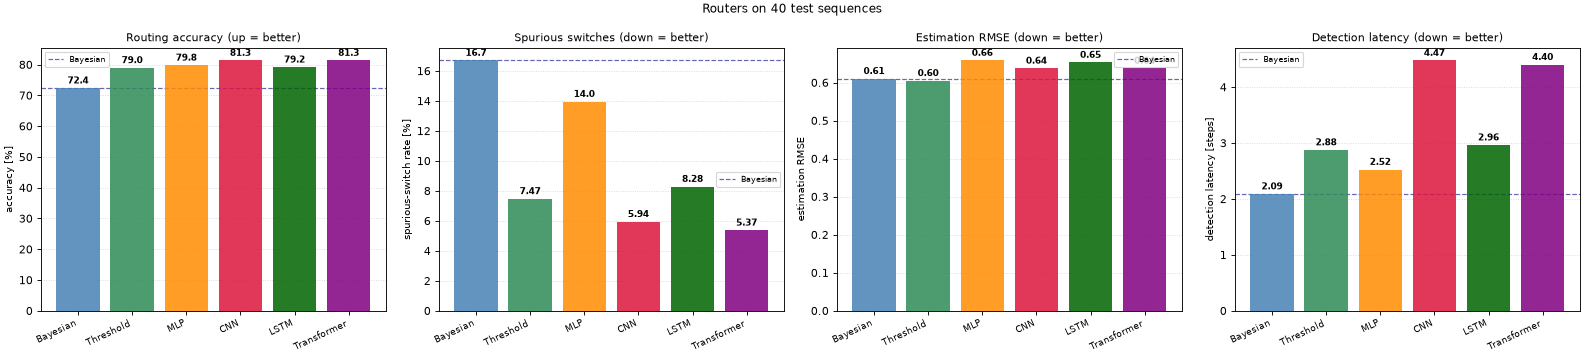

[cache] loading window_sweep.pkl (set KALMAN_CACHE_REFRESH=1 to recompute)

  window   accuracy   spurious    latency
       3      67.5%      16.2%       1.82
       5      73.1%      12.1%       1.75
       8      77.1%       9.2%       2.08
      10      79.4%       7.2%       2.48
      15      81.5%       6.2%       3.25
   Bayes      72.4%      16.7%       2.09   (reference)


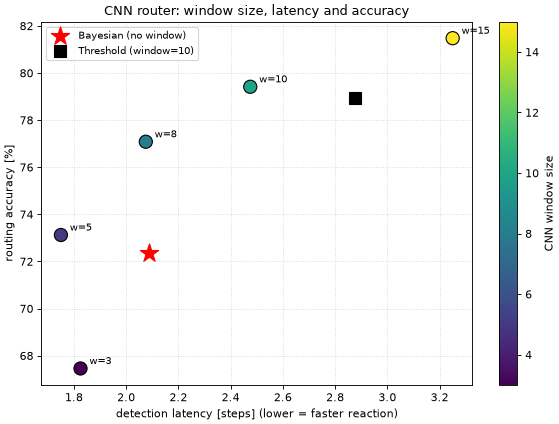


window 8 gives the latency closest to Bayesian's: 2.08 vs 2.09 steps, with accuracy 77.1% vs 72.4% and spurious switches 9.2% vs 16.7%


In [23]:
# ── Benchmark: 40 new sequences, alternating Gaussian / Student-t ────────
N_BENCH   = 40
SEG_LEN   = 60         # steps per regime segment
T_BENCH   = SEG_LEN * 4   # 2 full switches per sequence
SEED_BASE = 700

bench_routers = {
    "Bayesian":    BayesianRouter(),
    "Threshold":   ThresholdRouter(m=1, window=10, soft=True),
    "MLP":         all_routers["MLP"],
    "CNN":         all_routers["CNN"],
    "LSTM":        all_routers["LSTM"],
    "Transformer": all_routers["Transformer"],
}

def detection_latency(mu_arr, labels, threshold=0.5, regime=1, T=T_BENCH):
    """Steps from each ground-truth switch (→ regime) until μ first exceeds threshold."""
    lats = []
    switches = np.where(np.diff(labels) != 0)[0] + 1
    for sw in switches:
        if labels[sw] != regime:
            continue
        future = np.where(mu_arr[sw:, regime] > threshold)[0]
        lats.append(int(future[0]) if len(future) > 0 else T - sw)
    return float(np.mean(lats)) if lats else float("nan")

def _benchmark():
    # 40 sequences x 6 routers take a few minutes, so the table is cached.
    bench_metrics = {name: {"acc": [], "chatter": [], "rmse": [], "lat": []} for name in bench_routers}

    for i in range(N_BENCH):
        # the measurements and the true state that produced them
        z_seq, l_seq, x_seq = gen_switching(T_BENCH, SEG_LEN, seed=SEED_BASE + i, return_truth=True)

        for name, router in bench_routers.items():
            ikf_b = make_ikf(router=router)
            rec_b = ikf_b.forward(z_seq)
            mu_b   = np.array(ikf_b.mu_log)
            xest_b = np.array(rec_b.xk)[:, 0]

            bench_metrics[name]["acc"].append((np.argmax(mu_b, axis=1) == l_seq).mean())
            bench_metrics[name]["chatter"].append(chatter_rate(mu_b, l_seq))
            bench_metrics[name]["rmse"].append(float(np.sqrt(np.mean((xest_b - x_seq)**2))))
            bench_metrics[name]["lat"].append(detection_latency(mu_b, l_seq))

    return {name: {k: float(np.nanmean(v)) for k, v in m.items()} for name, m in bench_metrics.items()}

summary = cached(CACHE / "router_benchmark.pkl", _benchmark)

print(f"{'router':<14}  {'accuracy':>9}  {'spurious':>9}  {'RMSE':>9}  {'latency':>9}  {'trained':>8}")
print("─" * 68)
trained_flag = {"Bayesian": "No", "Threshold": "No",
                "MLP": "Yes", "CNN": "Yes", "LSTM": "Yes", "Transformer": "Yes"}
for name, s in summary.items():
    print(f"  {name:<12}  {s['acc']:>9.1%}  {s['chatter']:>9.1%}  {s['rmse']:>9.3f}  "
          f"{s['lat']:>9.1f}  {trained_flag[name]:>8}")


# ── Four-panel bar chart ─────────────────────────────────────────────────
names_bm  = list(summary)
metrics_bm = [
    ([summary[n]["acc"] * 100 for n in names_bm],     "accuracy [%]",                 "Routing accuracy (up = better)"),
    ([summary[n]["chatter"] * 100 for n in names_bm],  "spurious-switch rate [%]",     "Spurious switches (down = better)"),
    ([summary[n]["rmse"] for n in names_bm],            "estimation RMSE",              "Estimation RMSE (down = better)"),
    ([summary[n]["lat"] for n in names_bm],              "detection latency [steps]",   "Detection latency (down = better)"),
]
cols_bm = ["steelblue", "seagreen", "darkorange", "crimson", "darkgreen", "purple"]

fig, axes = plt.subplots(1, 4, figsize=(20, 4.6))
for ax, (vals, ylabel, title) in zip(axes, metrics_bm):
    bars = ax.bar(names_bm, vals, color=cols_bm[:len(names_bm)], alpha=0.85, zorder=3)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + max(vals)*0.01,
                f"{v:.2f}" if v < 10 else f"{v:.1f}", ha="center", va="bottom", fontsize=8, fontweight="bold")
    ax.axhline(vals[0], color="navy", ls="--", lw=1.1, alpha=0.6, label="Bayesian")
    ax.set_ylabel(ylabel, fontsize=9); ax.set_title(title, fontsize=10)
    ax.set_xticklabels(names_bm, rotation=25, ha="right", fontsize=8)
    ax.legend(fontsize=7); ax.grid(True, axis="y", ls=":", alpha=0.5, zorder=0)

fig.suptitle("Routers on 40 test sequences", fontsize=11)
plt.tight_layout(); plt.show()

# ── The CNN router with windows of 3 to 15 NIS values ────────────────────────

sweep_windows = [3, 5, 8, 10, 15]
def _sweep():
    # five CNNs trained and scored; cached like the benchmark above.
    sweep_results = {}
    for w in sweep_windows:
        router_w = NeuralRouter(model=CNN(out_channels=16, kernel_size=min(4, w)), window=w)
        ikf_w = make_ikf(router=router_w)
        ikf_w.fit(train_zk, train_lbl, epochs=200, lr=3e-3, seed=1)

        accs_w, chs_w, lats_w = [], [], []
        for i in range(20):
            z, l = gen_switching(T_BENCH, SEG_LEN, seed=SEED_BASE + i)
            ikf_e = make_ikf(router=router_w)
            ikf_e.forward(z)
            mu = np.array(ikf_e.mu_log)
            accs_w.append((np.argmax(mu, axis=1) == l).mean())
            chs_w.append(chatter_rate(mu, l))
            lats_w.append(detection_latency(mu, l))
        sweep_results[w] = dict(acc=np.mean(accs_w), chatter=np.mean(chs_w), lat=np.nanmean(lats_w))

    return sweep_results

sweep_results = cached(CACHE / "window_sweep.pkl", _sweep)

print(f"\n{'window':>8} {'accuracy':>10} {'spurious':>10} {'latency':>10}")
for w, r in sweep_results.items():
    print(f"{w:>8} {r['acc']*100:>9.1f}% {r['chatter']*100:>9.1f}% {r['lat']:>10.2f}")
print(f"{'Bayes':>8} {summary['Bayesian']['acc']*100:>9.1f}% "
      f"{summary['Bayesian']['chatter']*100:>9.1f}% {summary['Bayesian']['lat']:>10.2f}   (reference)")

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ws = sweep_windows
lats_sweep = [sweep_results[w]["lat"] for w in ws]
accs_sweep = [sweep_results[w]["acc"] * 100 for w in ws]
sc = ax.scatter(lats_sweep, accs_sweep, c=ws, cmap="viridis", s=140, zorder=3, edgecolor="k")
for w, x, y in zip(ws, lats_sweep, accs_sweep):
    ax.annotate(f"w={w}", (x, y), textcoords="offset points", xytext=(8, 4), fontsize=9)
ax.scatter([summary["Bayesian"]["lat"]], [summary["Bayesian"]["acc"] * 100],
           marker="*", s=300, color="red", zorder=4, label="Bayesian (no window)")
ax.scatter([summary["Threshold"]["lat"]], [summary["Threshold"]["acc"] * 100],
           marker="s", s=110, color="black", zorder=4, label="Threshold (window=10)")
ax.set_xlabel("detection latency [steps] (lower = faster reaction)")
ax.set_ylabel("routing accuracy [%]")
ax.set_title("CNN router: window size, latency and accuracy")
cbar = plt.colorbar(sc, ax=ax); cbar.set_label("CNN window size")
ax.legend(fontsize=9); ax.grid(True, ls=":", alpha=0.5)
plt.tight_layout(); plt.show()

best_w = min(sweep_windows, key=lambda w: abs(sweep_results[w]["lat"] - summary["Bayesian"]["lat"]))
print(f"\nwindow {best_w} gives the latency closest to Bayesian's: {sweep_results[best_w]['lat']:.2f} vs "
      f"{summary['Bayesian']['lat']:.2f} steps, with accuracy {sweep_results[best_w]['acc']*100:.1f}% vs "
      f"{summary['Bayesian']['acc']*100:.1f}% and spurious switches {sweep_results[best_w]['chatter']*100:.1f}% vs "
      f"{summary['Bayesian']['chatter']*100:.1f}%")

The routers that switch less often are not the ones with the best state estimate: the Bayesian and threshold routers give the lowest RMSE, and the neural routers a few percent more. Fewer spurious switches did not give a better estimate of the state. The CNN and Transformer routers also take about twice as many steps as the Bayesian one to notice a real switch.

The window sweep shows the trade-off: with a window of 8 the CNN reacts as fast as the Bayesian router and is still more accurate and steadier; a longer window is steadier still but slower, a shorter one less accurate.

## Summary

| Question | What this notebook found |
|---|---|
| Can a learned controller beat LQR when the steering stays below its limit? | No. LQR is optimal there, and the network, imitating a short-horizon MPPI planner, cost three times as much. Heavy-tailed noise did not change the LQR cost. |
| Does planning around a hard steering limit beat clipped LQR? | Not in cost. MPPI and its network overshot less than half as far as LQR, but their total cost was equal or a few percent higher, with Gaussian or heavy-tailed noise. |
| Must adapting $\mathbf{Q}$ be learned? | Not for noise that changes in the measured state: a rule on the innovation variance lowered the error by about 30%. For noise in the heading, which the rule hardly sees, a small classifier helped, but it recognised that case less than half of the time. |
| Does learned routing beat Bayes' rule with heavy-tailed noise? | It switched spuriously less often and was a few points more accurate, but the untrained `ThresholdRouter` got most of that gain, and the state estimate was not better: the Bayesian and threshold routers gave the lowest RMSE. With Gaussian noise the Bayesian router was best. |

In every case the filter itself was the classical Kalman filter; the learned parts only chose a control, a noise level, or a model weight. Each had to be compared not only with the textbook method but also with a simple rule, and with the quantity that matters in the end (cost, or state error), not only with the quantity the network was trained on.